# Лабораторная работа 1  
### ПРЕДВАРИТЕЛЬНЫЙ СТАТИСТИЧЕСКИЙ АНАЛИЗ ДАННЫХ

ЗАДАЧИ ИССЛЕДОВАНИЯ
1. Исследовать основные описательные статистики для каждого коэффициента
(минимум, максимум, среднее, медиана, стандартное отклонение) с целью ознакомления с
особенностями данных и их распределением.
2. Провести графический анализ данных с целью анализа их распределения на
основе построения гистограмм.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PowerTransformer, MinMaxScaler
import os
from IPython.display import display, Image, HTML
from statsmodels.stats.stattools import medcouple

In [2]:
outdir = 'plots'
os.makedirs(outdir, exist_ok=True)

In [3]:
df = pd.read_spss(r'.\data\data_lab1_start.sav')
df.head(3)
print(df.describe())
print(df.count())
df.drop(columns=["Cреднеспис.числ.работн", "Year", "k4_new"], inplace = True)

       Cреднеспис.числ.работн           k1           k2           k3  \
count             2695.000000  2695.000000  2695.000000  2695.000000   
mean              1220.773284     2.002089     0.238018     0.825098   
std               2556.406482     1.690052     0.517697     0.918292   
min                 10.000000     0.248322     0.000000     0.008329   
25%                229.500000     1.097990     0.017088     0.317674   
50%                473.000000     1.473859     0.055551     0.538349   
75%               1128.500000     2.238232     0.211538     0.941372   
max              28650.000000    18.020148     7.029135    11.187699   

                k4       k4_new           k5           k6           k7  \
count  2695.000000  1540.000000  2695.000000  2695.000000  2695.000000   
mean      0.038115     0.335777     0.346330     0.238031     0.174212   
std       0.625155     0.360196     0.198008     0.213094     0.223266   
min      -4.569874    -2.599123     0.009944     0.0000

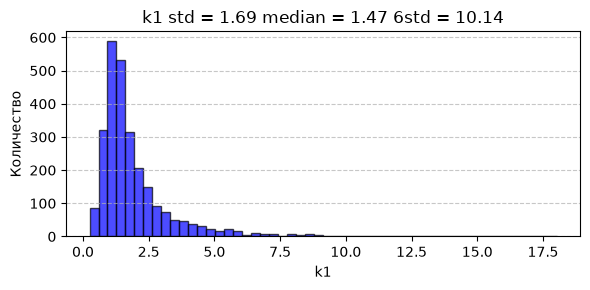

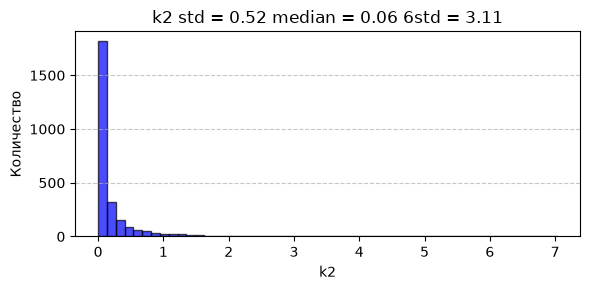

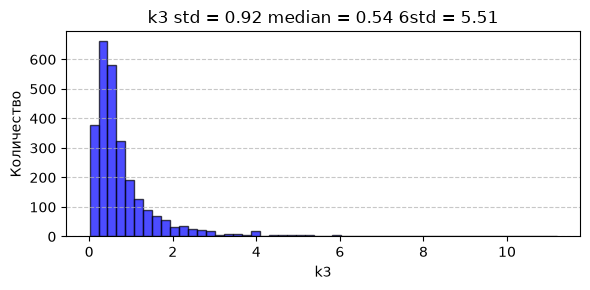

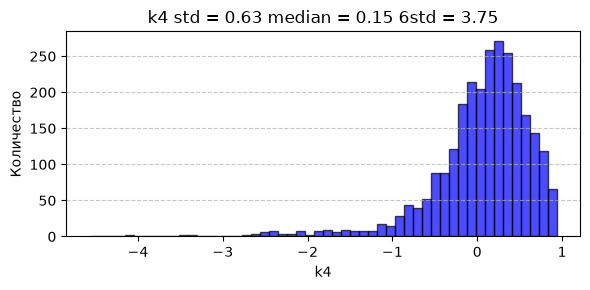

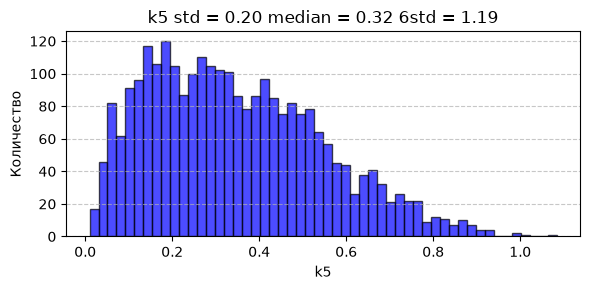

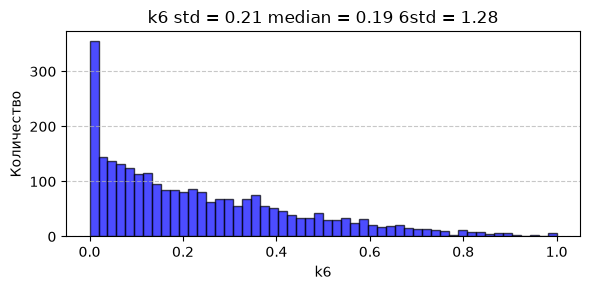

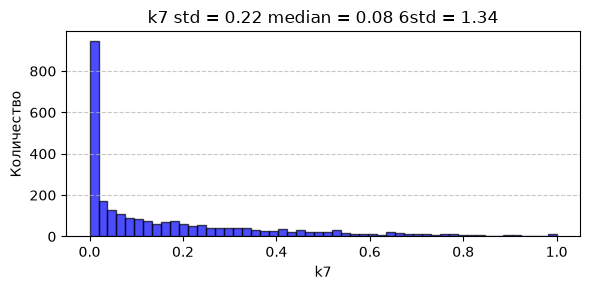

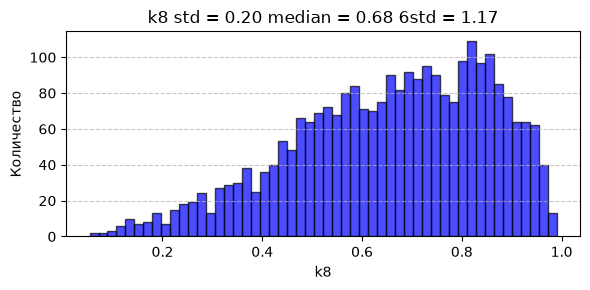

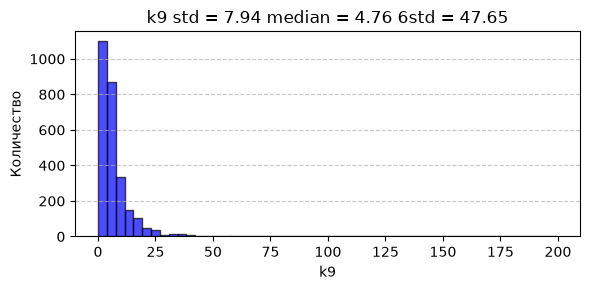

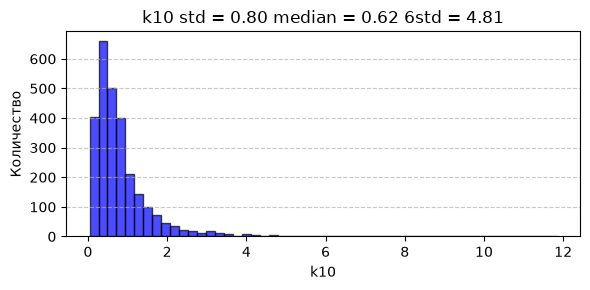

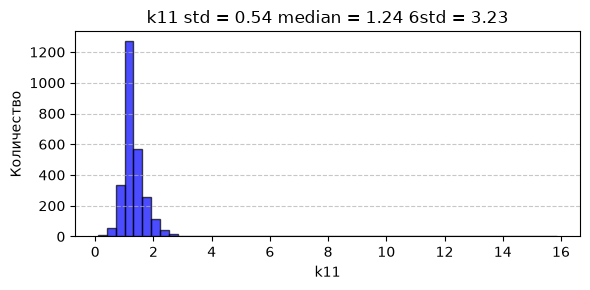

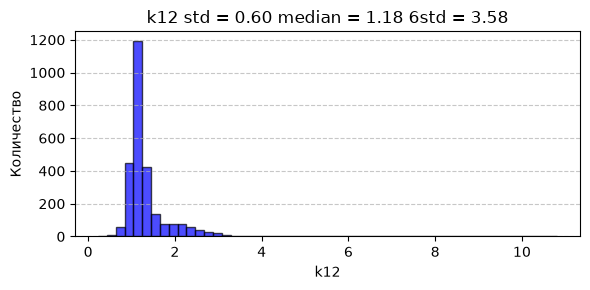

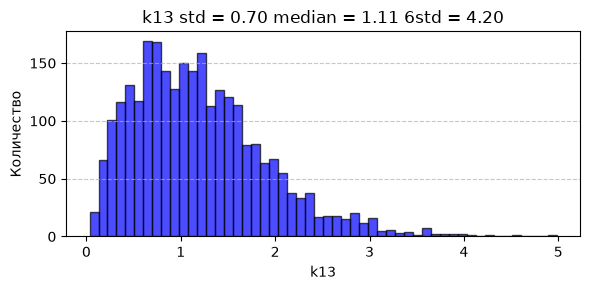

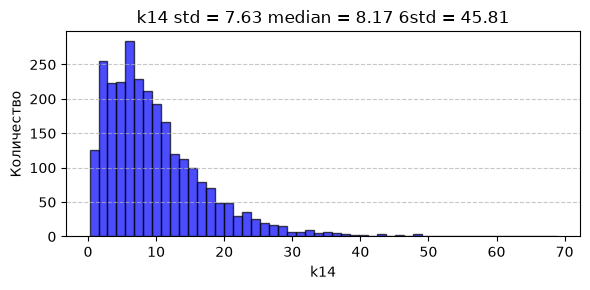

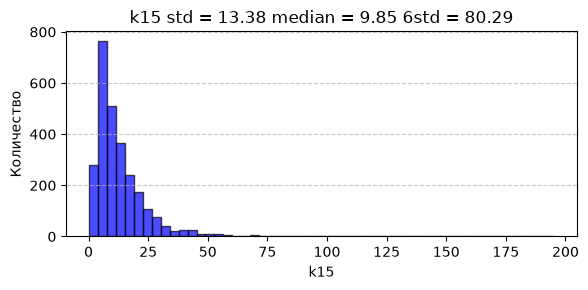

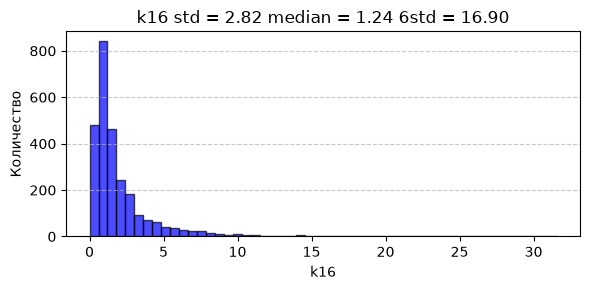

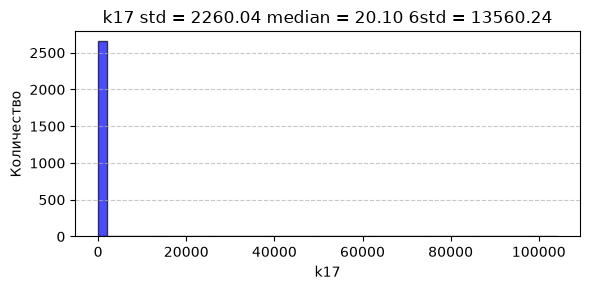

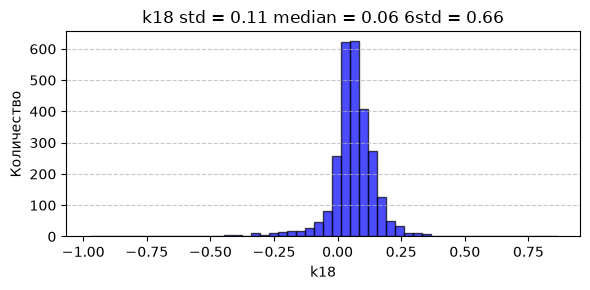

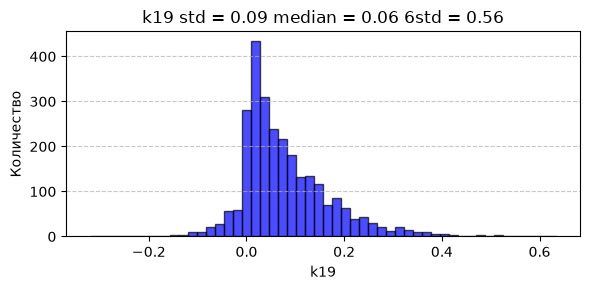

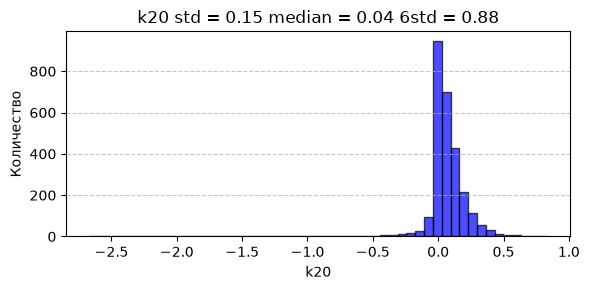

In [4]:
num_cols = df.select_dtypes(include=['number']).columns
for col in num_cols:
    plt.figure(figsize=(6,3))
    plt.hist(df[col].dropna(), bins=52, color='blue', edgecolor='black', alpha=0.7)
    plt.title(f"{col} std = {np.std(df[col].dropna()):.2f} median = {np.median(df[col].dropna()):.2f} 6std = {(6 * np.std(df[col].dropna())):.2f}")
    plt.xlabel(col)
    plt.ylabel("Количество")
    plt.grid(axis='y', linestyle='--', alpha = 0.7)
    plt.tight_layout() 
    plt.savefig(f'{outdir}/{col}_hist1.png')
    plt.show()

Похожим на нормальное распределение являются коэффициенты К18-К20  

ЗАДАЧИ ИССЛЕДОВАНИЯ
1. Провести графический анализ данных с целью выявления аномальных
наблюдений на основе построения ящичных диаграмм.
2. На основании условия ниже или «правила шести сигм» определить экстремальные
наблюдения в выборке. Множитель в это условие подобрать таким образом, чтобы
экстремальными признавалось не более 5-8% наблюдений
3. Провести цензурирование и нормировку данных.

$$[x_{med} - 5.2 \cdot x_{mad}, \ x_{med} + 5.2 \cdot x_{mad}]$$

где:
* $x_{med}$ — медиана выборки $\{x_i\}$
* $x_{mad}$ — медиана выборки $\{|x_i - x_{med}|\} \ (i = \overline{1, n})$ абсолютных отклонений от $x_{med}$


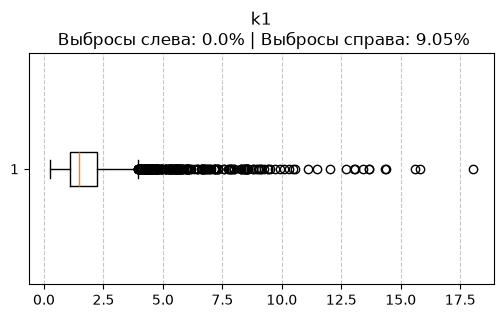

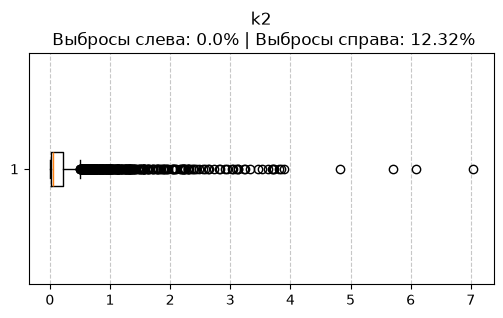

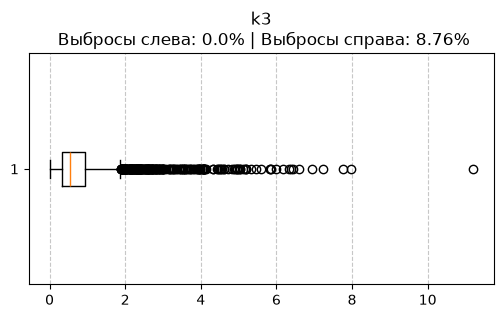

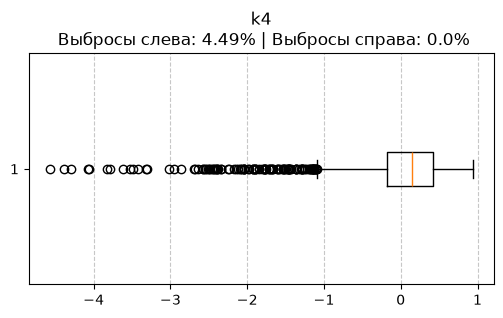

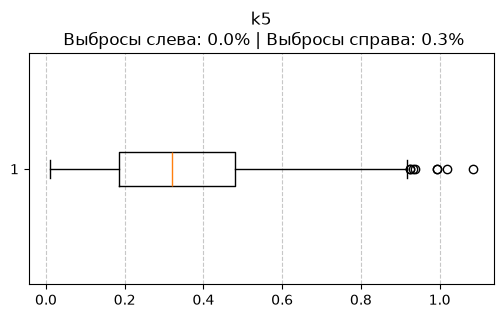

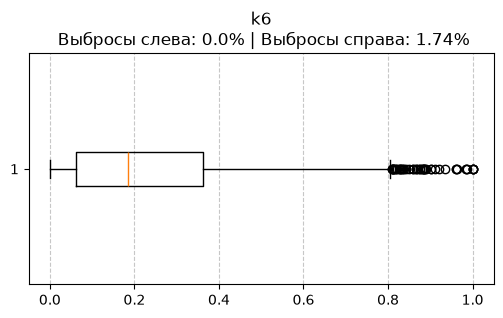

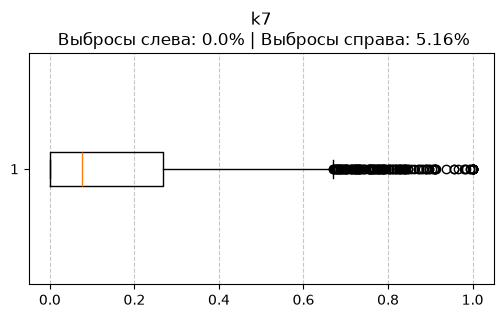

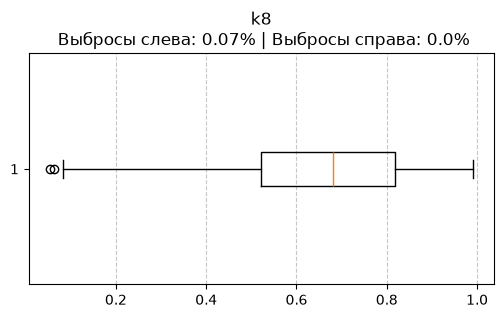

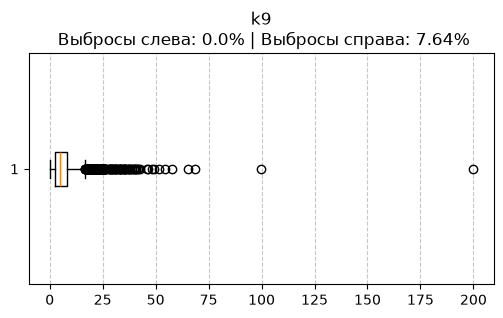

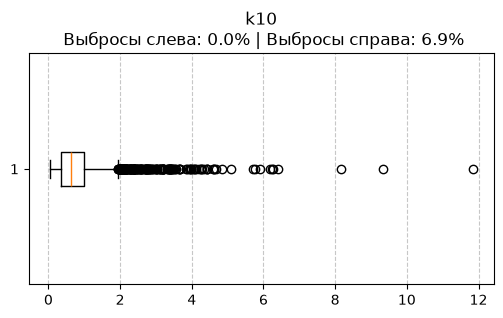

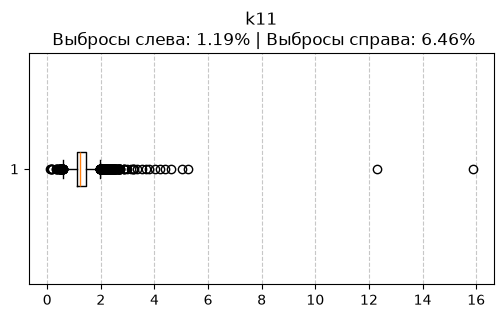

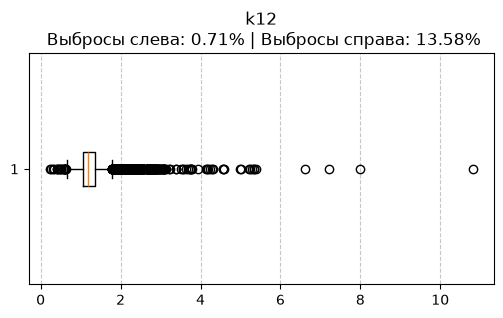

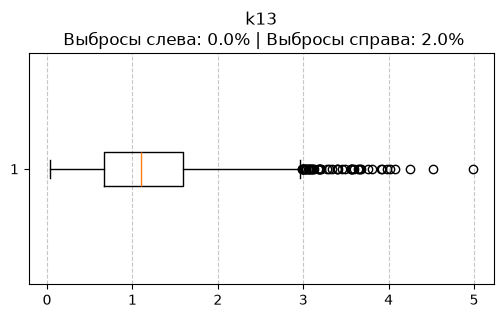

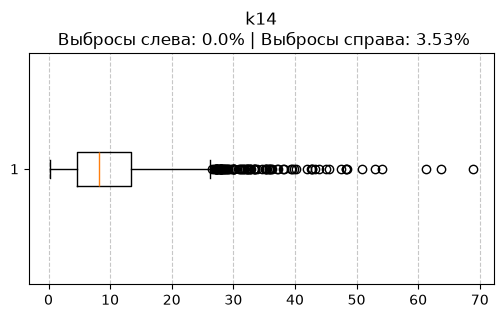

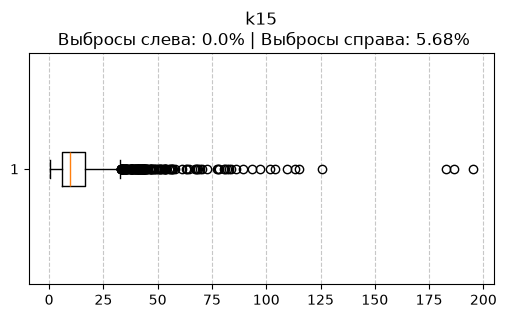

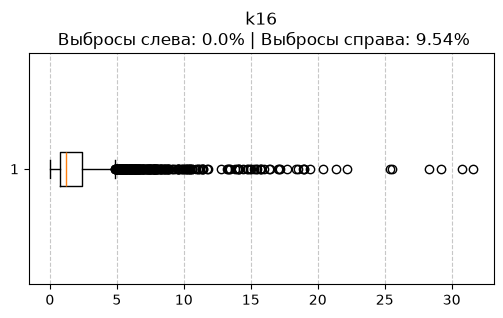

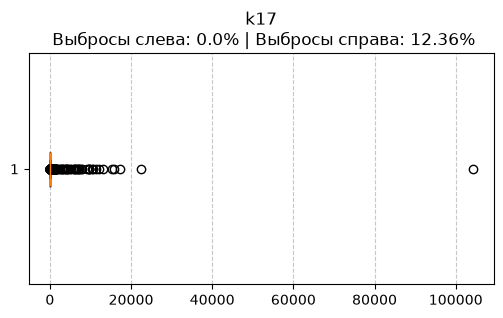

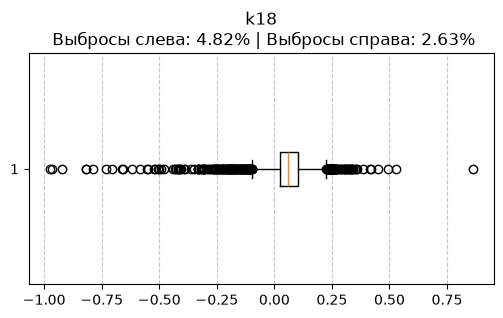

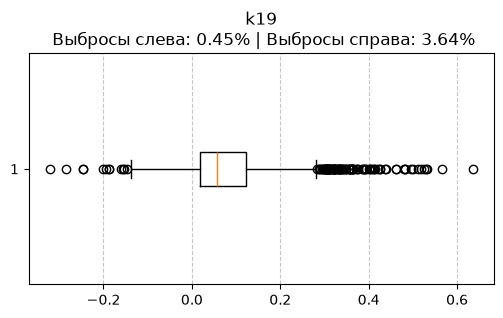

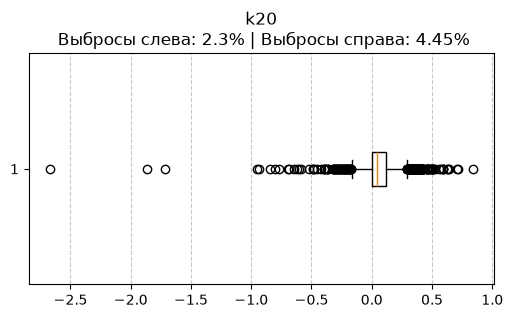

Итоговая статистика:
k1: Выбросы слева: 0.0% | Выбросы справа: 9.05%
k2: Выбросы слева: 0.0% | Выбросы справа: 12.32%
k3: Выбросы слева: 0.0% | Выбросы справа: 8.76%
k4: Выбросы слева: 4.49% | Выбросы справа: 0.0%
k5: Выбросы слева: 0.0% | Выбросы справа: 0.3%
k6: Выбросы слева: 0.0% | Выбросы справа: 1.74%
k7: Выбросы слева: 0.0% | Выбросы справа: 5.16%
k8: Выбросы слева: 0.07% | Выбросы справа: 0.0%
k9: Выбросы слева: 0.0% | Выбросы справа: 7.64%
k10: Выбросы слева: 0.0% | Выбросы справа: 6.9%
k11: Выбросы слева: 1.19% | Выбросы справа: 6.46%
k12: Выбросы слева: 0.71% | Выбросы справа: 13.58%
k13: Выбросы слева: 0.0% | Выбросы справа: 2.0%
k14: Выбросы слева: 0.0% | Выбросы справа: 3.53%
k15: Выбросы слева: 0.0% | Выбросы справа: 5.68%
k16: Выбросы слева: 0.0% | Выбросы справа: 9.54%
k17: Выбросы слева: 0.0% | Выбросы справа: 12.36%
k18: Выбросы слева: 4.82% | Выбросы справа: 2.63%
k19: Выбросы слева: 0.45% | Выбросы справа: 3.64%
k20: Выбросы слева: 2.3% | Выбросы справа: 4.45%


In [5]:
summary = {}

for col in num_cols:
    plt.figure(figsize=(6,3))
    bp = plt.boxplot(df[col].dropna(), orientation='horizontal')

    total_count = len(df[col].dropna())
    left_whisker = bp['whiskers'][0].get_xdata()[1]   
    right_whisker= bp['whiskers'][1].get_xdata()[1]
    noise = bp['fliers'][0].get_xdata()

    left_noise_count = len(noise[noise < left_whisker])
    right_noise_count = len(noise[noise > right_whisker])

    if total_count > 0:
        left_prc = round((left_noise_count / total_count) * 100, 2)
        right_prc = round((right_noise_count / total_count) * 100, 2)
    else:
        left_prc = right_prc = 0.0

    summary[col] = {
        'total_count': total_count,
        'left_noise_count': left_noise_count,
        'right_noise_count': right_noise_count,
        'left_prc': left_prc,
        'right_prc': right_prc
    }


    plt.title(f"{col}\n Выбросы слева: {left_prc}% | Выбросы справа: {right_prc}%")
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.savefig(f'{outdir}/{col}_box1.png')
    plt.show()

print("Итоговая статистика:")
for stat, data in summary.items():
    print(f"{stat}: Выбросы слева: {data['left_prc']}% | Выбросы справа: {data['right_prc']}%")

k1:  6.72% 181
k2:  6.98% 188
k3:  6.75% 182
k4:  6.46% 174
k5:  3.30% 89
k6:  5.45% 147
k7:  6.68% 180
k8:  3.27% 88
k9:  6.86% 185
k10:  6.86% 185
k11:  6.46% 174
k12:  6.83% 184
k13:  5.34% 144
k14:  6.09% 164
k15:  6.27% 169
k16:  6.68% 180
k17:  6.98% 188
k18:  6.42% 173
k19:  6.27% 169
k20:  6.86% 185


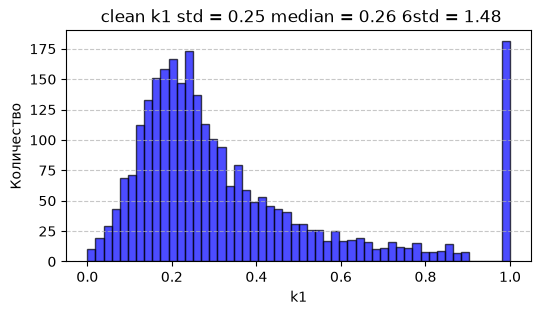

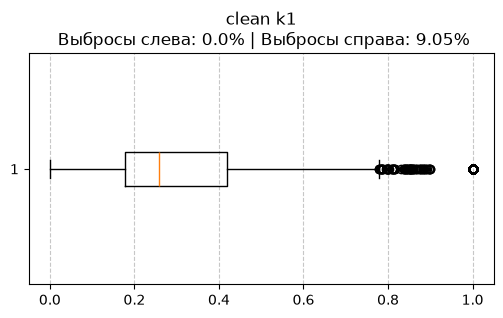

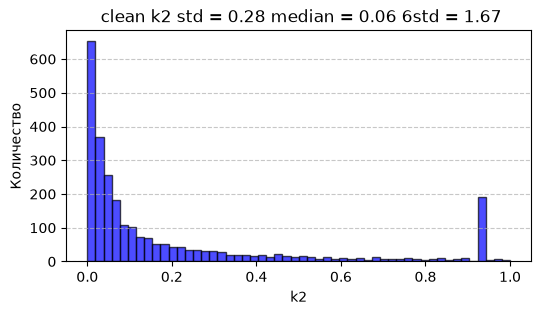

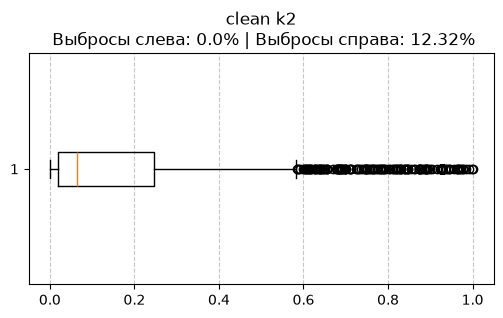

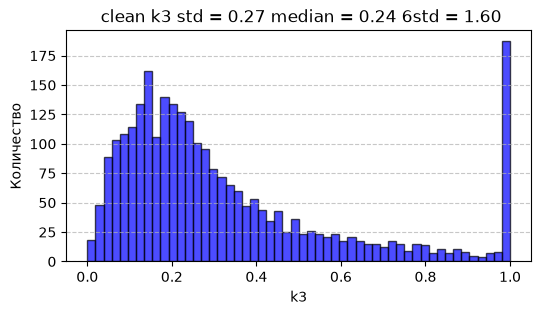

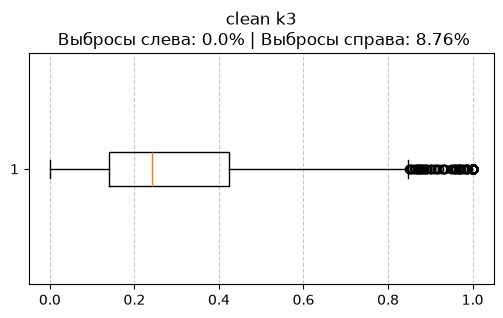

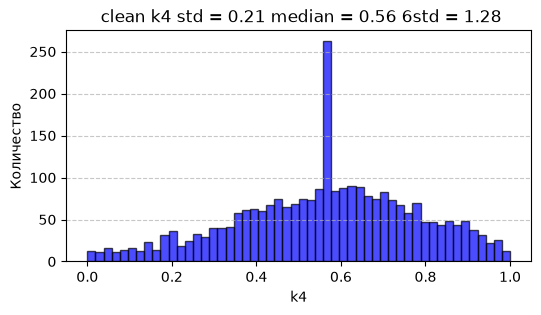

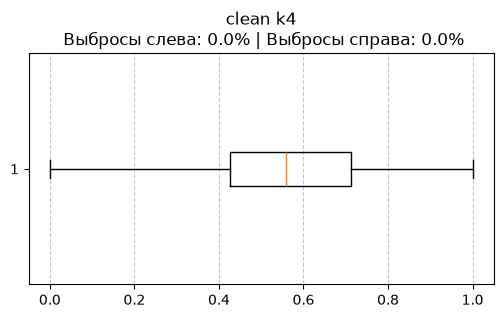

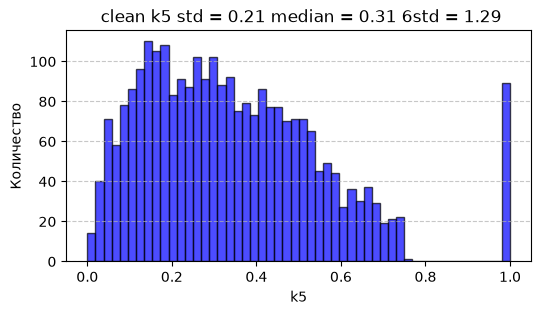

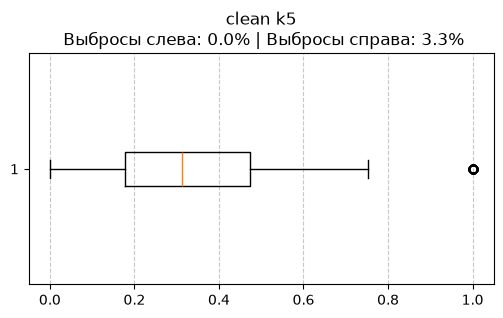

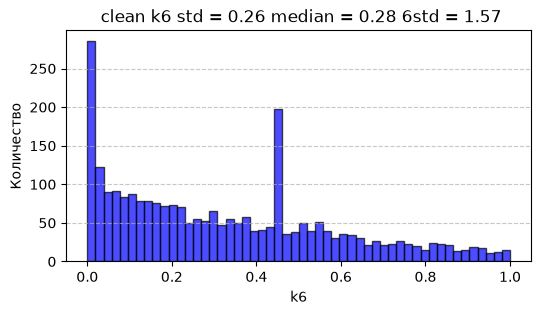

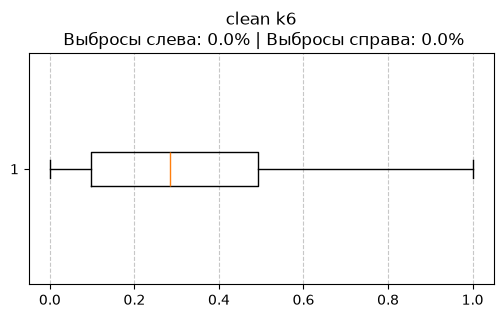

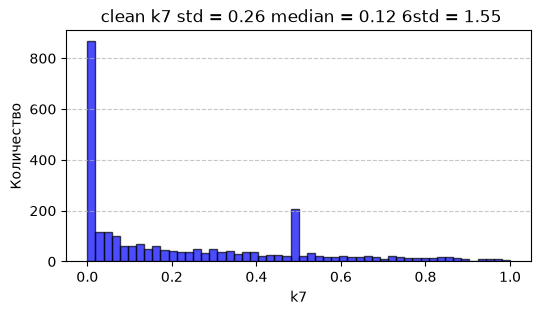

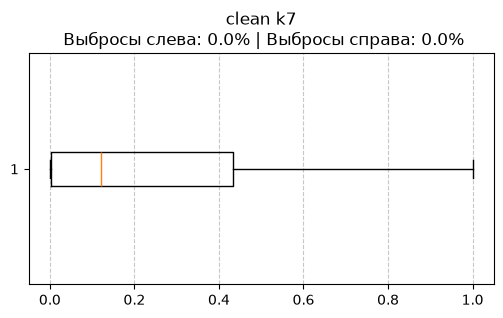

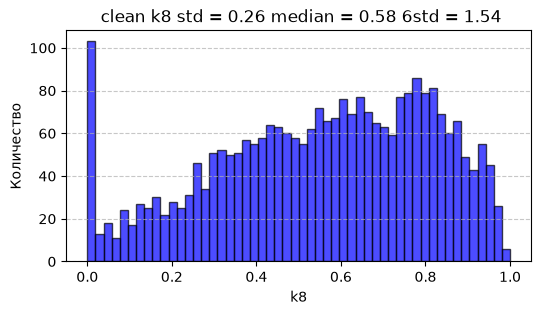

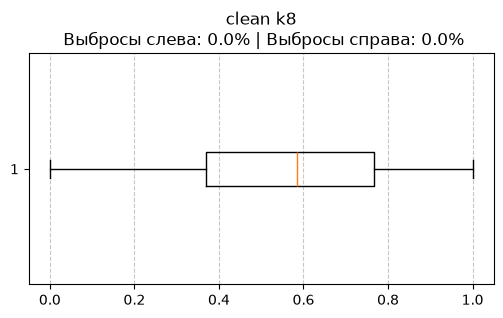

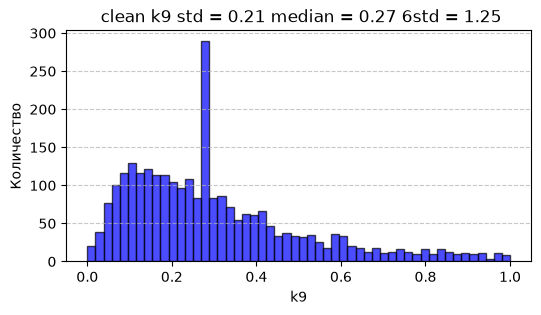

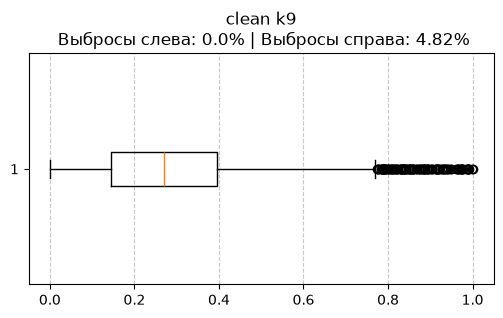

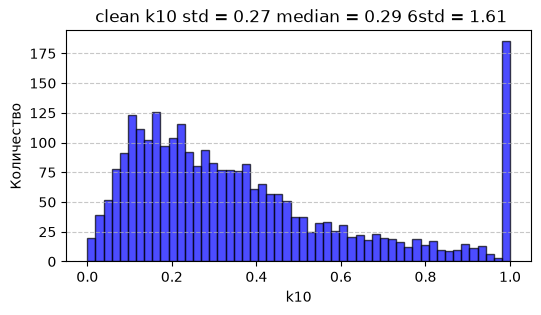

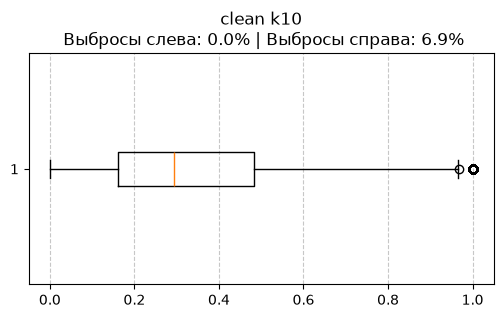

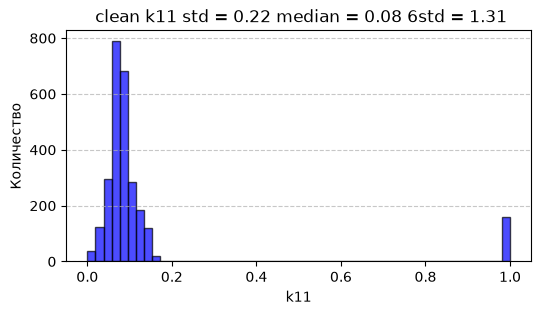

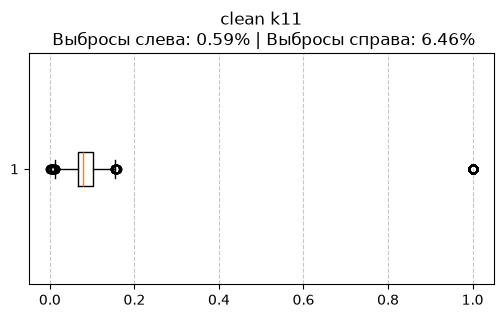

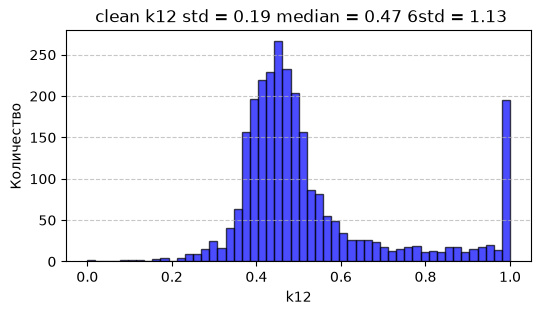

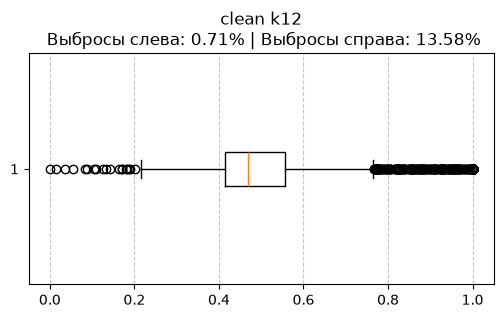

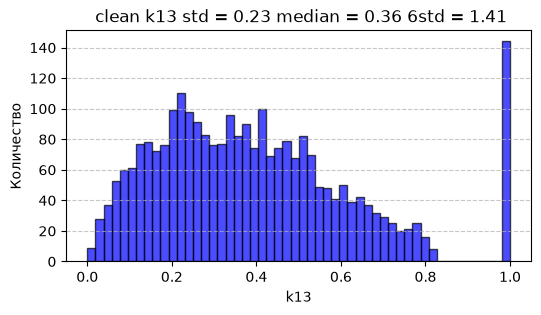

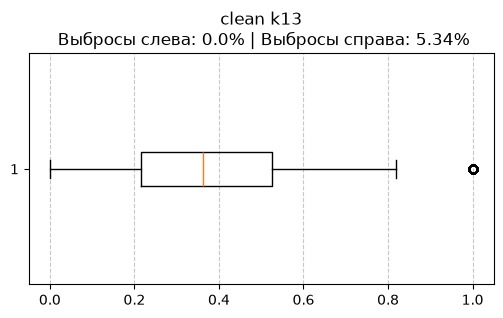

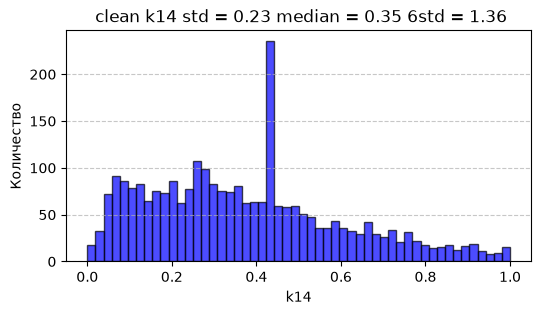

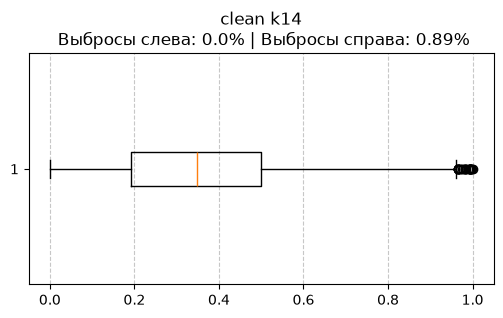

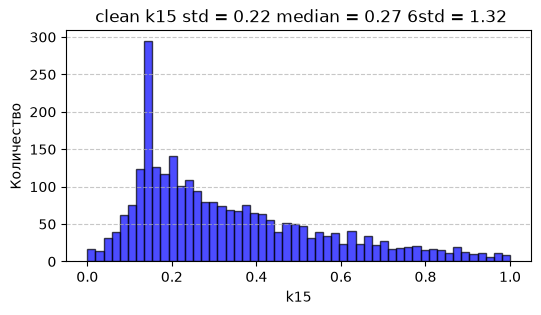

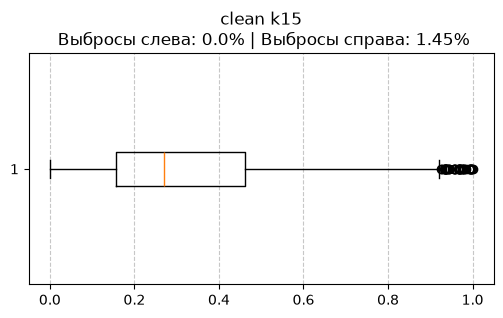

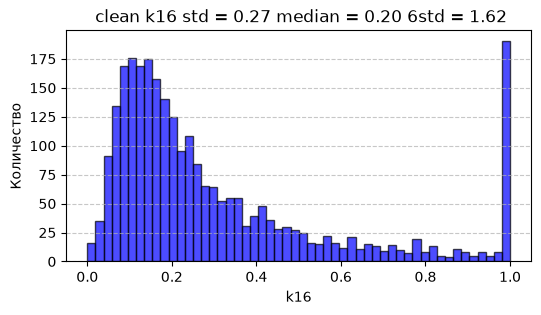

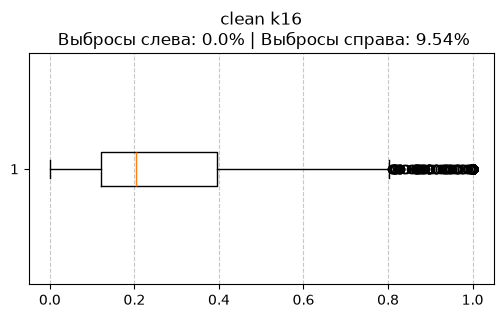

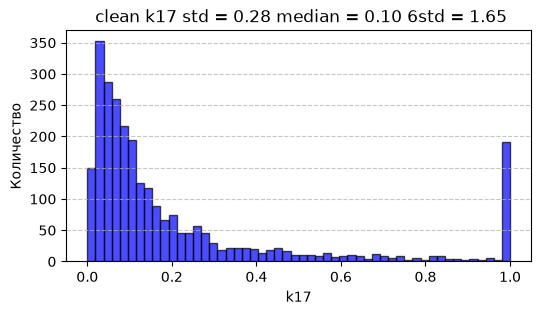

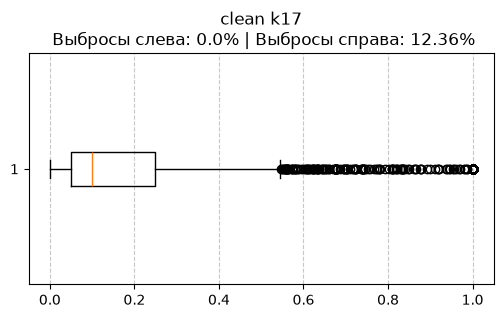

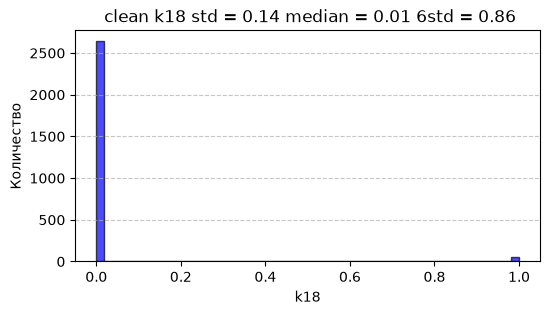

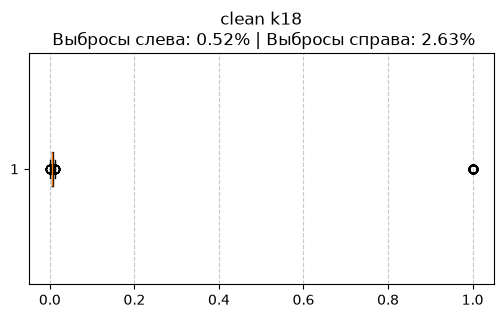

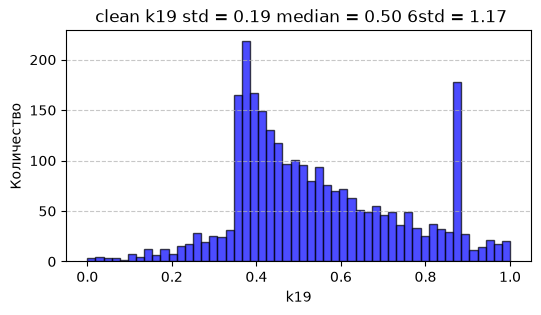

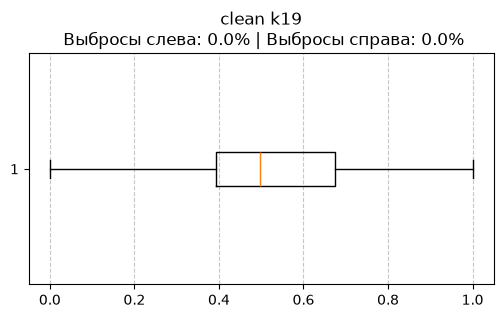

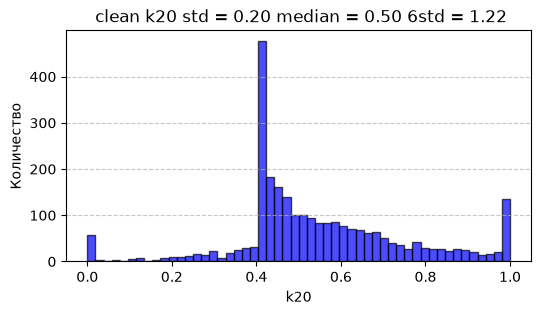

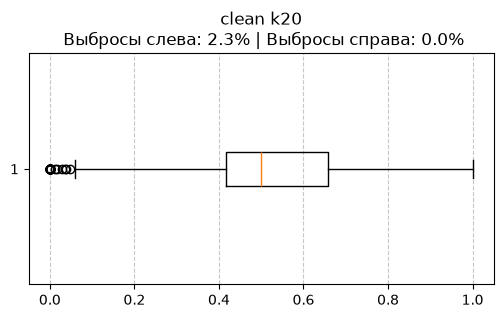

In [6]:
def hampel_test(data, col, dict_ = None, mul=3):
    working_data = data.copy()
    perc = 1
    while perc > 0.07:
        clean_data = data.dropna()
        med = clean_data.median()
        mad = (clean_data - med).abs().median()
        left_bound = med - mul * mad
        right_bound = med + mul * mad
        mask = (clean_data < left_bound) | (clean_data > right_bound)
        perc = mask.sum() / len(clean_data)
        mul += 0.3
    if col in dict_:
        low_val = dict_[col][0]   
        high_val = dict_[col][1]  
    else:
        low_val = left_bound
        high_val = right_bound
    working_data.loc[working_data < left_bound] = low_val
    working_data.loc[working_data > right_bound] = high_val
    print(f"{(perc * 100):.2f}% {mask.sum()}")
    return working_data

K = {
    'k1': (1.0, 5.0),
    'k2': (0.05, 0.8),
    'k4': (0.15, 1.0),
    'k5': (0.0, 1.0),
    'k6': (0.0, 0.3),
    'k7': (0.0, 0.3),
    'k9': (0.8, 5.0),
    'k10': (0.3, 2.0),
    'k11': (1.0, 10.0),
    'k13': (0.5, 3.0),
    'k14': (1.0, 10.0),
    'k15': (0.0, 5.0),
    'k18': (0.0, 30.0),
    'k19': (0.0, 0.2)
}


df_clean = df.copy()
for col in num_cols:
    print(f"{col}: ", end=' ')
    df_clean[col] = hampel_test(df[col], dict_=K, col=col)

mmscaler = MinMaxScaler()
df_no_na = df_clean.dropna()
df_scaled = pd.DataFrame(
    mmscaler.fit_transform(df_no_na), 
    columns=df_no_na.columns, 
    index=df_no_na.index
)

for col in num_cols:
    plt.figure(figsize=(6,3))
    plt.hist(df_scaled[col].dropna(), bins=52, color='blue', edgecolor='black', alpha=0.7)
    plt.title(f" clean {col} std = {np.std(df_scaled[col].dropna()):.2f} median = {np.median(df_scaled[col].dropna()):.2f} 6std = {(6 * np.std(df_scaled[col].dropna())):.2f}")
    plt.xlabel(col)
    plt.ylabel("Количество")
    plt.grid(axis='y', linestyle='--', alpha = 0.7)
    plt.savefig(f'{outdir}/{col}_hist2.png')
    plt.show()
    
    plt.figure(figsize=(6,3))
    bp = plt.boxplot(df_scaled[col].dropna(), orientation='horizontal')

    total_count = len(df_scaled[col].dropna())
    left_whisker = bp['whiskers'][0].get_xdata()[1]   
    right_whisker= bp['whiskers'][1].get_xdata()[1]
    noise = bp['fliers'][0].get_xdata()

    left_noise_count = len(noise[noise < left_whisker])
    right_noise_count = len(noise[noise > right_whisker])

    if total_count > 0:
        left_prc = round((left_noise_count / total_count) * 100, 2)
        right_prc = round((right_noise_count / total_count) * 100, 2)
    else:
        left_prc = right_prc = 0.0

    summary[col] = {
        'total_count': total_count,
        'left_noise_count': left_noise_count,
        'right_noise_count': right_noise_count,
        'left_prc': left_prc,
        'right_prc': right_prc
    }


    plt.title(f"clean {col}\n Выбросы слева: {left_prc}% | Выбросы справа: {right_prc}%")
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.savefig(f'{outdir}/{col}_box2.png')
    plt.show()

    

После удаления шума с помощью теста Хампеля получили более читаемы боксплоты, но все равно в них достаточно много объектов классифицируются как шумовые. Удалять их нельзя, потому что это приведет к сильному сокращению выборки

### 1. Расчет коэффициента Medcouple (MC)

Для выборки $\{x_1, \dots, x_n\}$ коэффициент **Medcouple (MC)** определяется как медиана значений функции ядра $h(x_i, x_j)$, вычисленная по всем парам, для которых $x_i \leq Q_2 \leq x_j$:

$$MC = \operatorname{med}_{x_i \leq Q_2 \leq x_j} h(x_i, x_j)$$

Где $Q_2$ — медиана выборки, а функция ядра $h(x_i, x_j)$ для всех $x_i \neq x_j$ рассчитывается по формуле:

$$h(x_i, x_j) = \frac{(x_j - Q_2) - (Q_2 - x_i)}{x_j - x_i}$$

---

### 2. Границы Adjusted Boxplot с учетом MC

После расчета $MC$ границы усов определяются следующим образом ($IQR = Q_3 - Q_1$):

**Если $MC \geq 0$ (положительная асимметрия):**
$$\text{Нижний ус} = Q_1 - 1.5 \cdot e^{-4 \cdot MC} \cdot IQR$$
$$\text{Верхний ус} = Q_3 + 1.5 \cdot e^{3 \cdot MC} \cdot IQR$$

**Если $MC < 0$ (отрицательная асимметрия):**
$$\text{Нижний ус} = Q_1 - 1.5 \cdot e^{-3 \cdot MC} \cdot IQR$$
$$\text{Верхний ус} = Q_3 + 1.5 \cdot e^{4 \cdot MC} \cdot IQR$$

**Ограничение по реальным границам данных:**
$$\text{Итоговый нижний ус} = \max(\text{Нижний ус}, \min(X))$$
$$\text{Итоговый верхний ус} = \min(\text{Верхний ус}, \max(X))$$


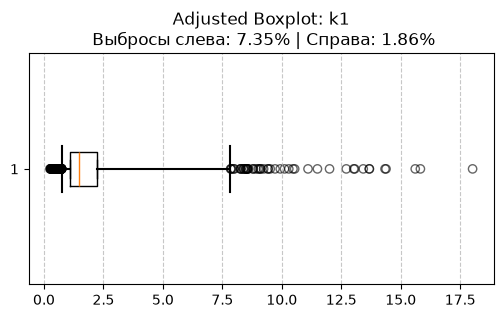

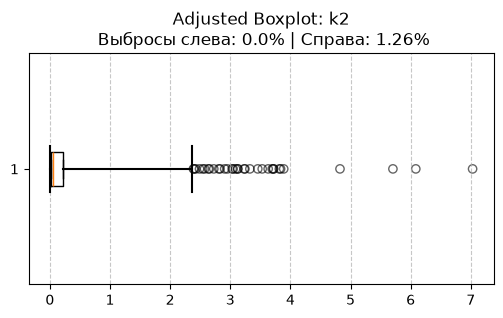

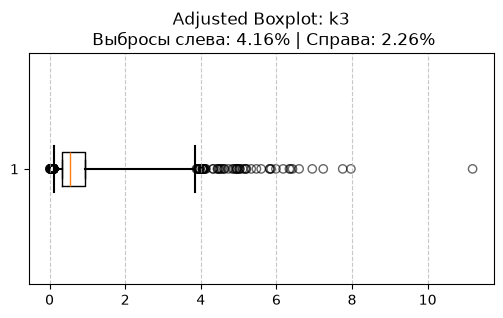

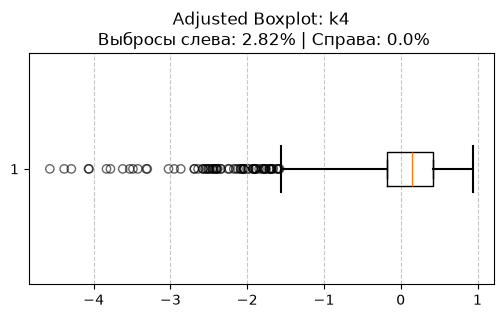

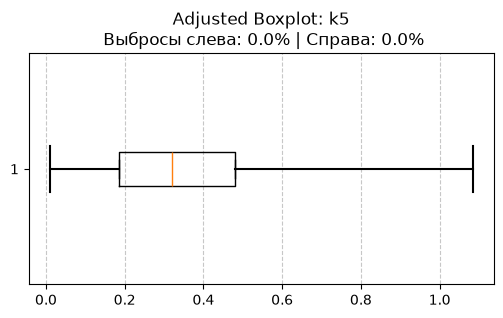

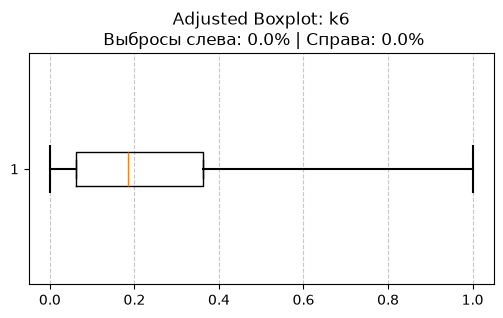

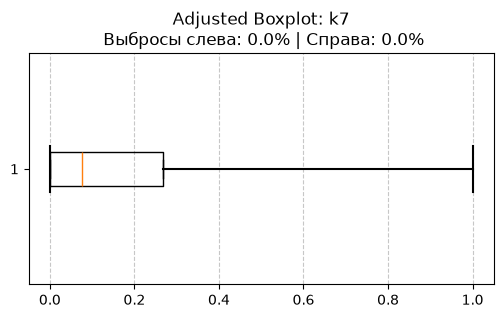

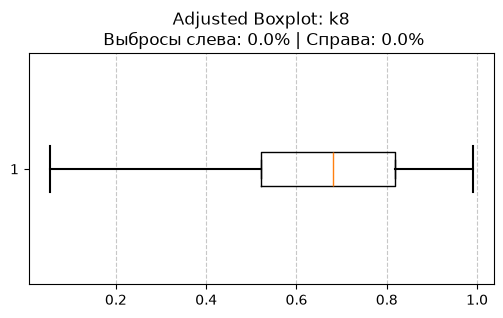

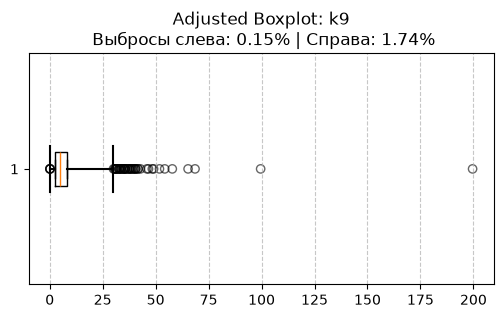

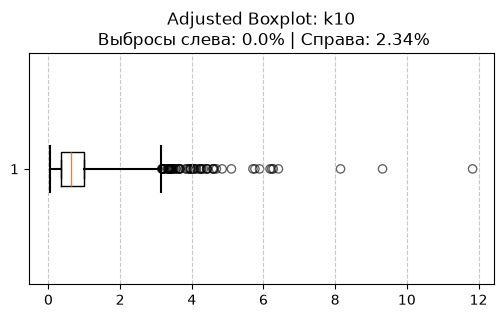

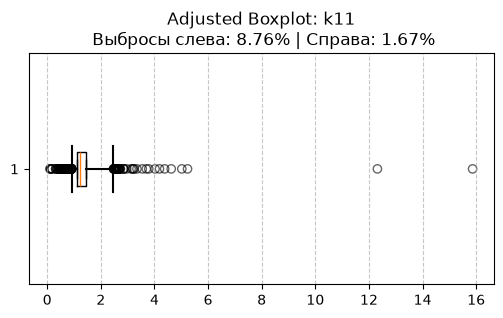

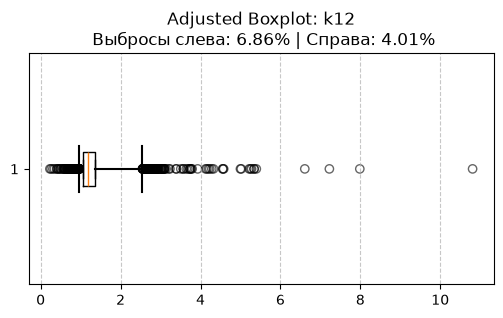

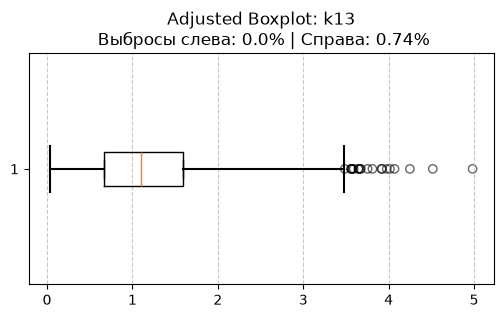

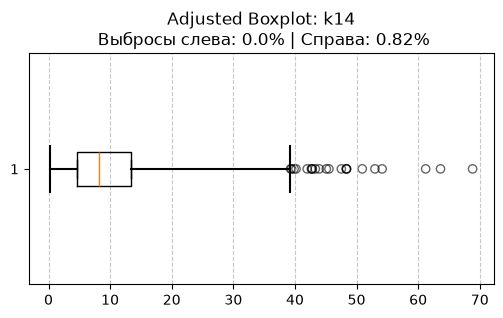

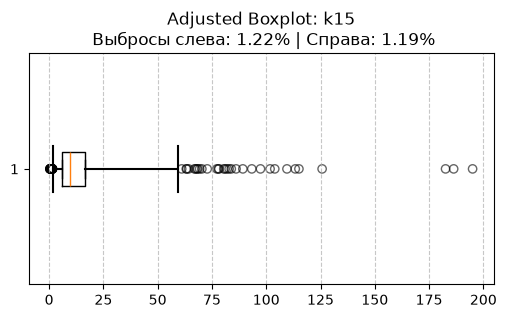

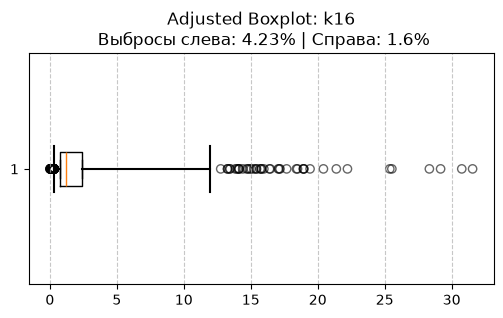

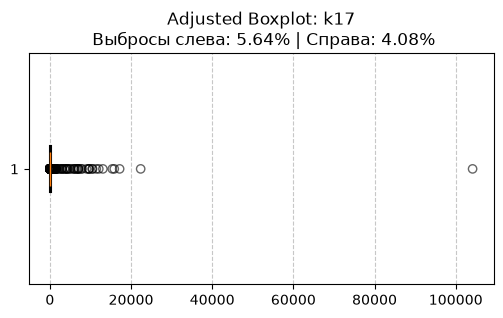

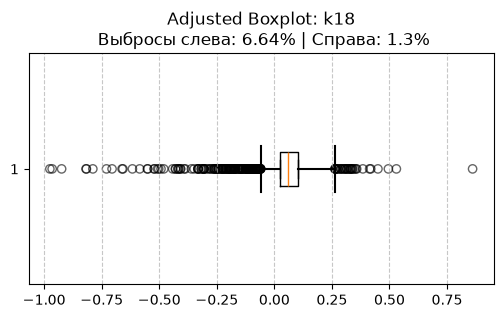

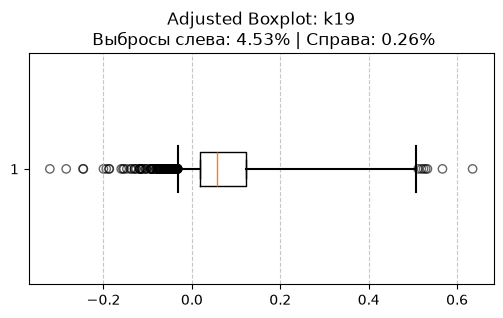

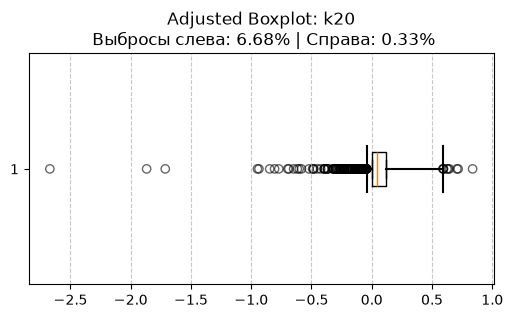

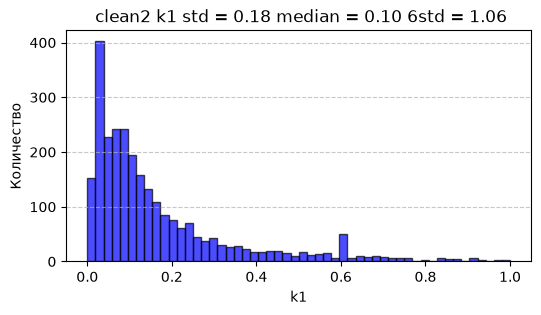

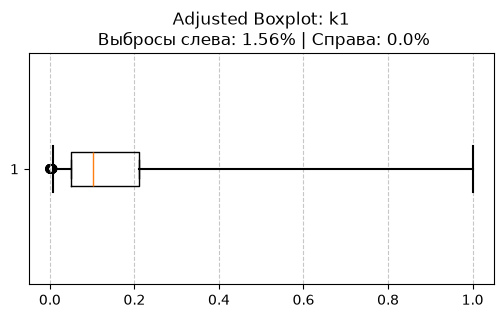

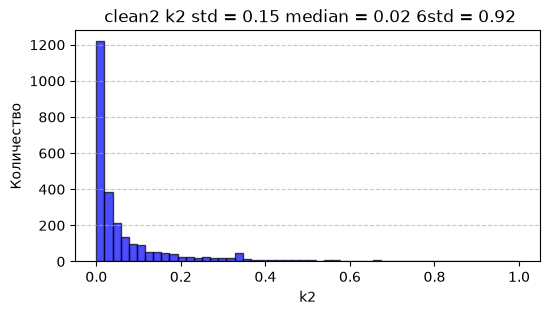

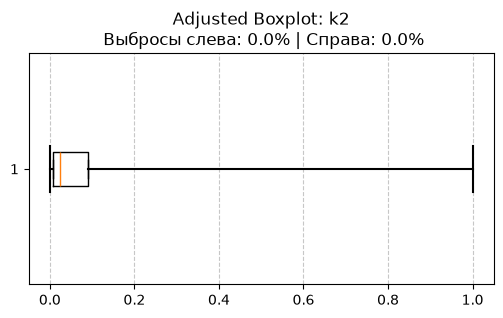

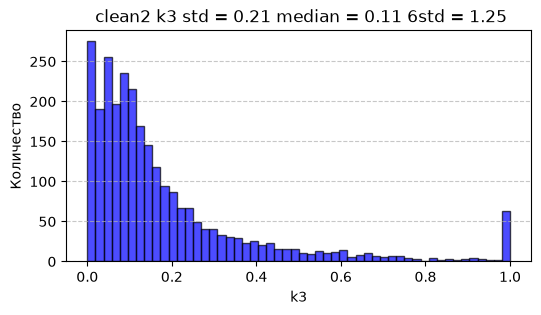

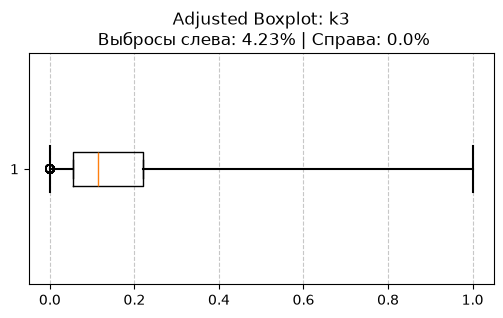

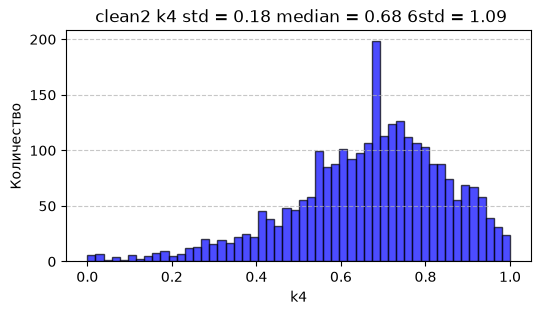

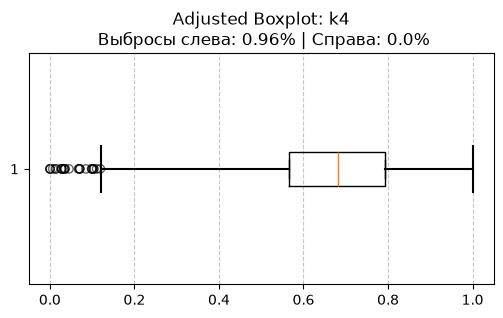

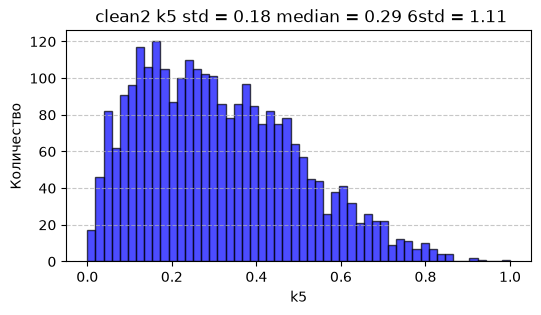

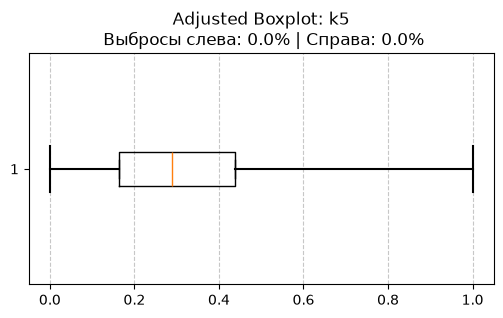

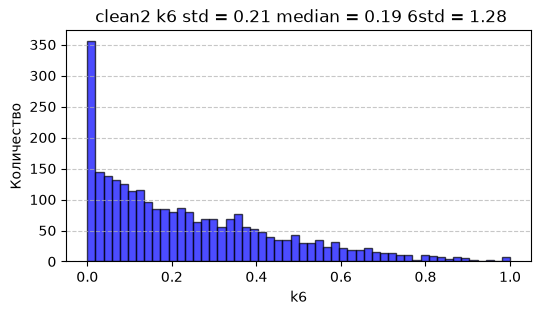

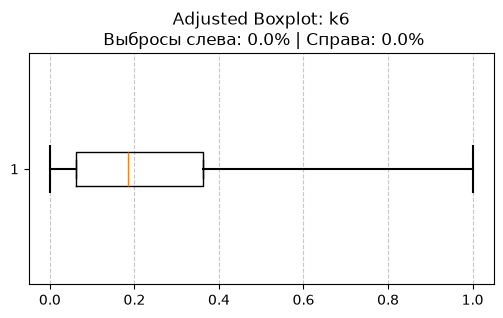

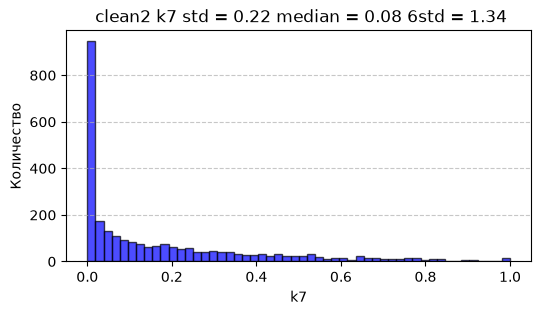

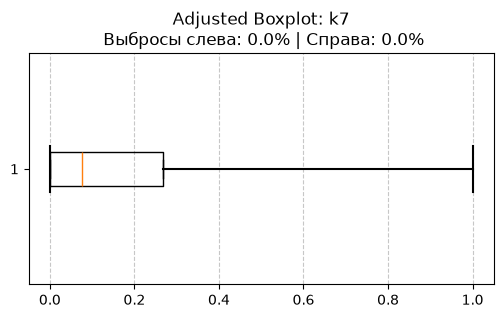

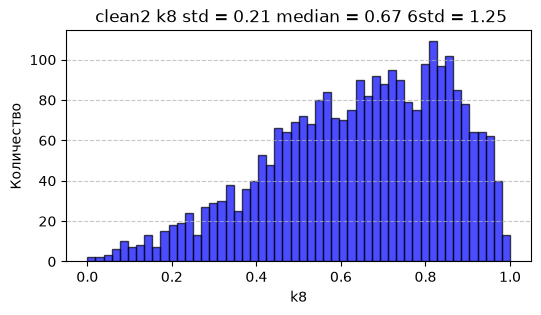

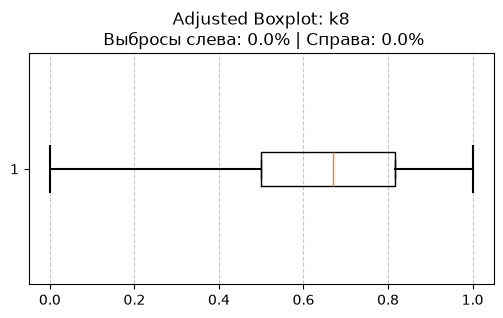

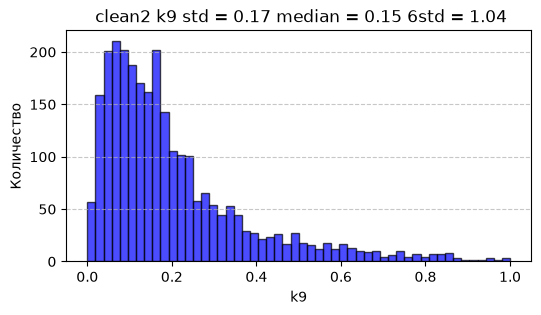

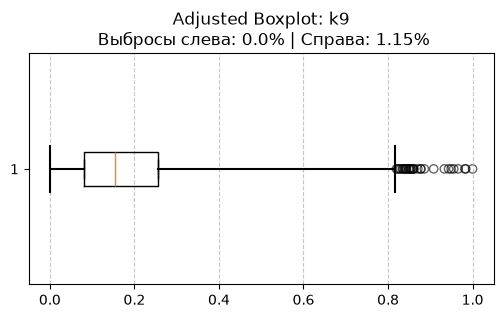

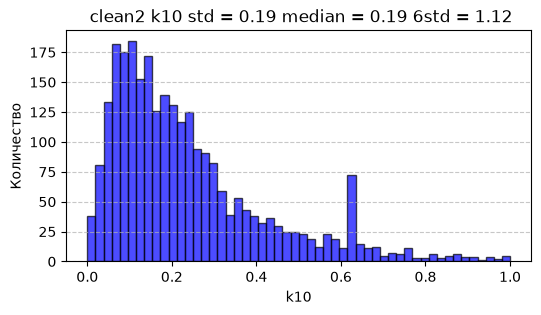

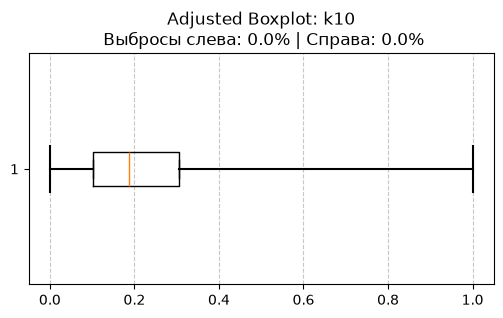

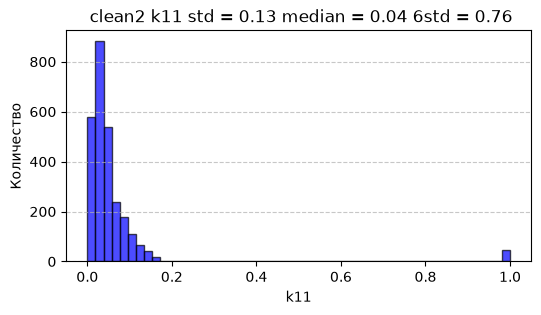

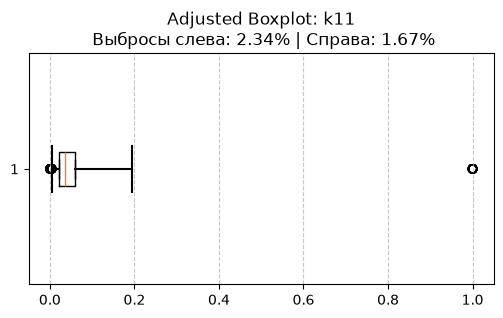

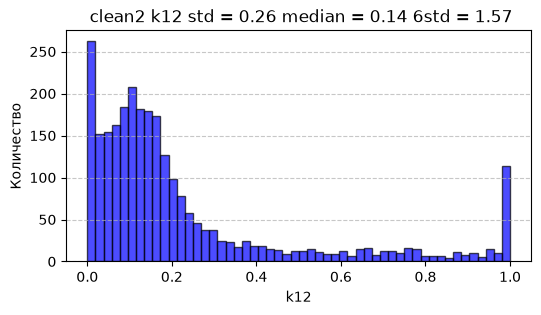

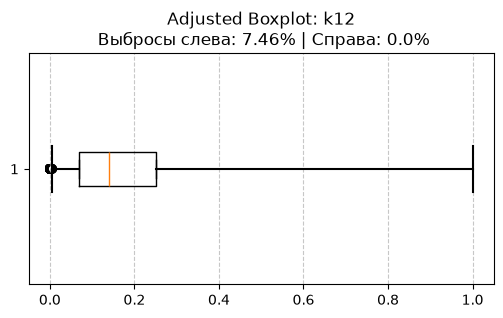

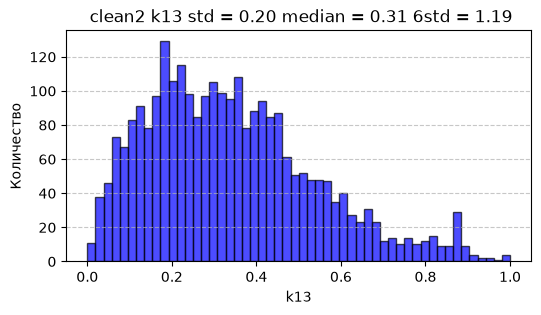

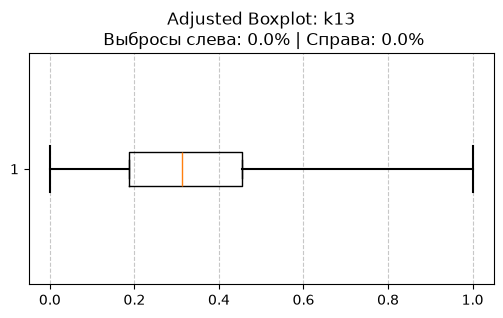

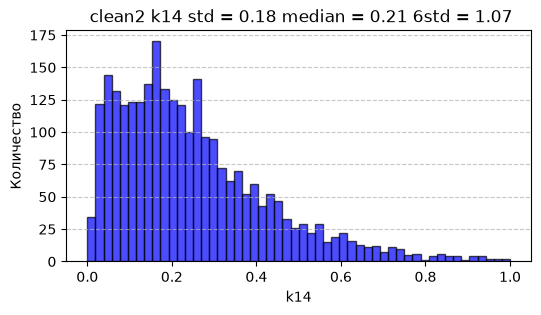

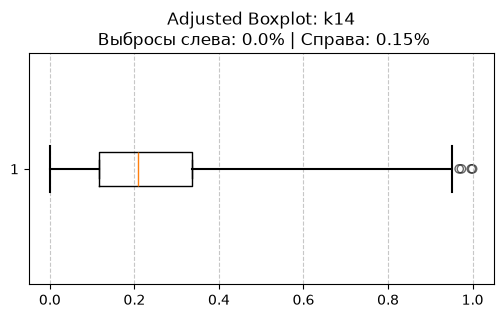

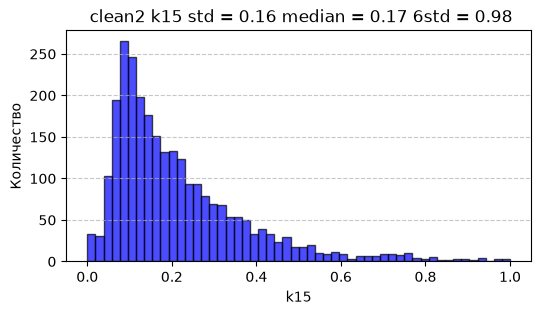

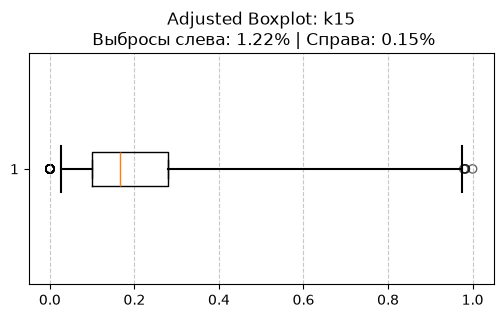

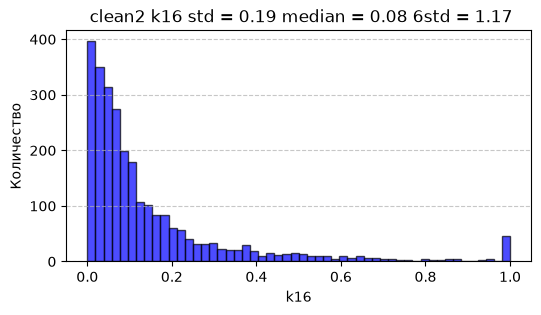

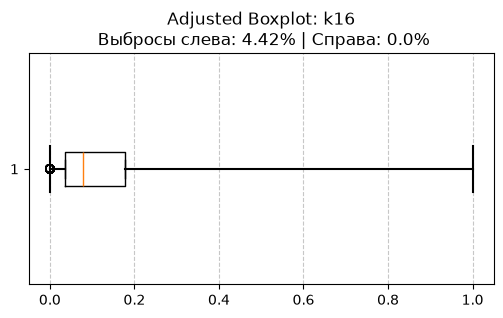

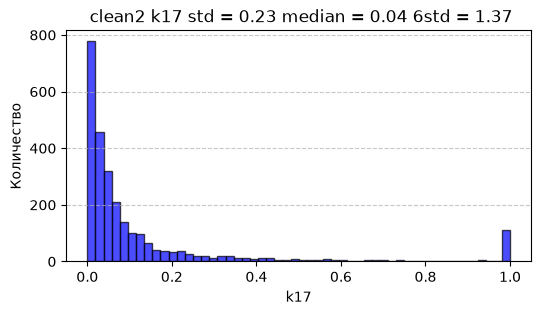

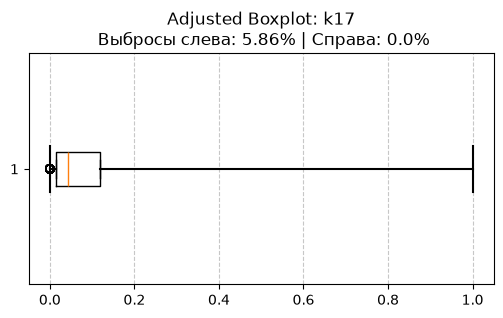

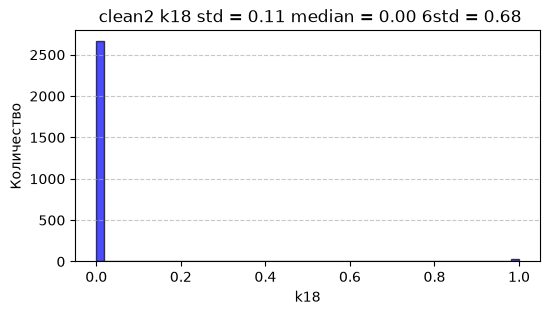

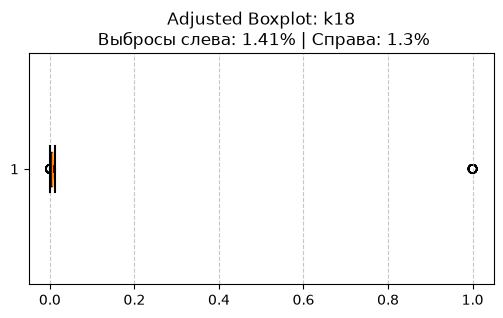

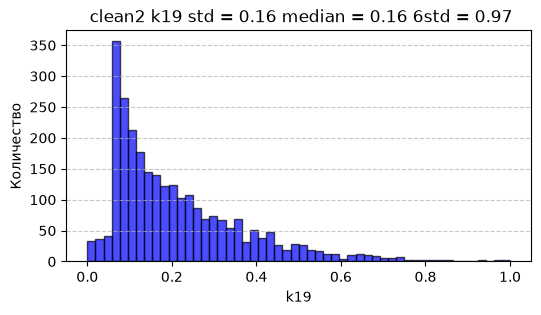

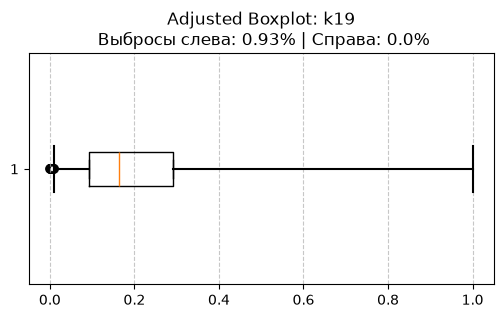

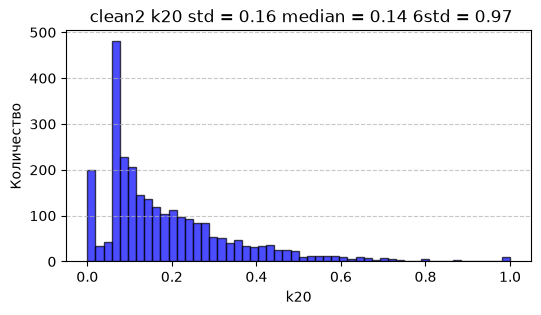

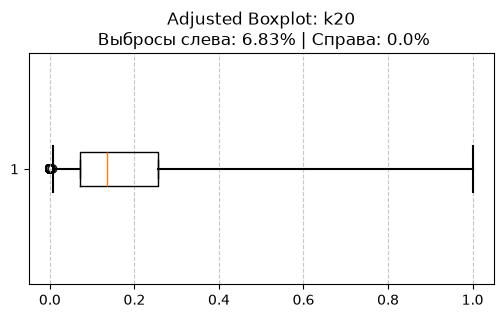

In [7]:
def adj_boxplot(data, dict_ = None, num = 3):
    series_copy = data.copy()
    clean_data = data.dropna().to_numpy()
    col_name = data.name    

    q25, q75 = np.percentile(clean_data, [25, 75])
    iqr = q75 - q25
    mc = medcouple(clean_data)

    if mc >= 0:
        left_whisker = q25 - 1.5 * np.exp(-4 * mc) * iqr
        right_whisker = q75 + 1.5 * np.exp(3 * mc) * iqr
    else:
        left_whisker = q25 - 1.5 * np.exp(-3 * mc) * iqr
        right_whisker = q75 + 1.5 * np.exp(4 * mc) * iqr

    left_whisker = max(left_whisker, clean_data.min())
    right_whisker = min(right_whisker, clean_data.max())
    outliers = clean_data[(clean_data < left_whisker) | (clean_data > right_whisker)]
    
    total_count = len(clean_data)
    left_outliers = outliers[outliers < left_whisker]
    right_outliers = outliers[outliers > right_whisker]
    
    left_prc = round((len(left_outliers) / total_count) * 100, 2)
    right_prc = round((len(right_outliers) / total_count) * 100, 2)

    plt.figure(figsize=(6, 3))
    bp = plt.boxplot(clean_data, orientation='horizontal', positions=[1], showfliers=False, whis=0)
    
    plt.plot([left_whisker, q25], [1, 1], color='black', linestyle='-')
    plt.plot([q75, right_whisker], [1, 1], color='black', linestyle='-')
    

    plt.plot([left_whisker, left_whisker], [0.9, 1.1], color='black', linestyle='-')
    plt.plot([right_whisker, right_whisker], [0.9, 1.1], color='black', linestyle='-')
    
    if len(left_outliers) > 0:
        plt.scatter(left_outliers, np.ones_like(left_outliers), color='black', facecolors='none', edgecolors='black', alpha=0.6)
    if len(right_outliers) > 0:
        plt.scatter(right_outliers, np.ones_like(right_outliers), color='black', facecolors='none', edgecolors='black', alpha=0.6)
        
    
    plt.title(f"Adjusted Boxplot: {col_name}\n Выбросы слева: {left_prc}% | Справа: {right_prc}%")
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.ylim(0.5, 1.5) 
    plt.savefig(f'{outdir}/{col_name}_box{num}.png')
    plt.show()
    if num == 3:
        if col_name in dict_:
            low_val = dict_[col_name][0]   
            high_val = dict_[col_name][1]  
        else:
            low_val = left_whisker  
            high_val = right_whisker
        series_copy.loc[series_copy < left_whisker] = low_val
        series_copy.loc[series_copy > right_whisker] = high_val
        return series_copy

df_clean2 = df.copy()
for col in num_cols:
    df_clean2[col] = adj_boxplot(df[col], K)

df_no_na = df_clean2.dropna()
df_scaled2 = pd.DataFrame(
    mmscaler.fit_transform(df_no_na), 
    columns=df_no_na.columns, 
    index=df_no_na.index
)


for col in num_cols:
    plt.figure(figsize=(6,3))
    plt.hist(df_scaled2[col].dropna(), bins=52, color='blue', edgecolor='black', alpha=0.7)
    plt.title(f" clean2 {col} std = {np.std(df_scaled2[col].dropna()):.2f} median = {np.median(df_scaled2[col].dropna()):.2f} 6std = {(6 * np.std(df_scaled2[col].dropna())):.2f}")
    plt.xlabel(col)
    plt.ylabel("Количество")
    plt.grid(axis='y', linestyle='--', alpha = 0.7)
    plt.savefig(f'{outdir}/{col}_hist4.png')
    plt.show()
    
    adj_boxplot(df_scaled2[col], K, num=5)


$$
\psi(\lambda, x) = 
\begin{cases} 
\frac{(x + 1)^\lambda - 1}{\lambda} & \text{если } x \ge 0, \lambda \neq 0 \\ 
\ln(x + 1) & \text{если } x \ge 0, \lambda = 0 \\ 
-\frac{(-x + 1)^{2 - \lambda} - 1}{2 - \lambda} & \text{если } x < 0, \lambda \neq 2 \\ 
-\ln(-x + 1) & \text{если } x < 0, \lambda = 2 
\end{cases}
$$


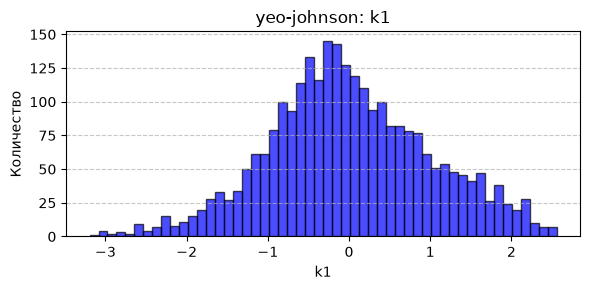

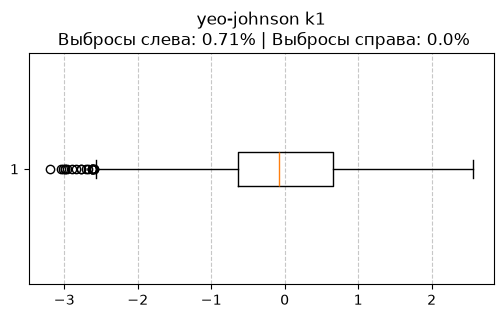

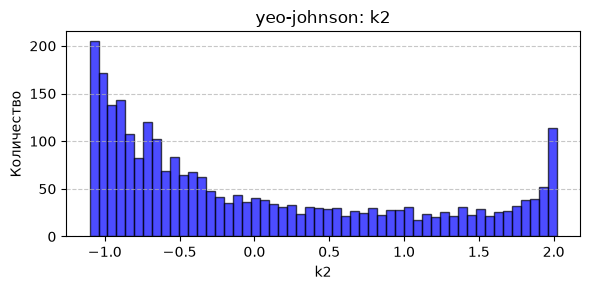

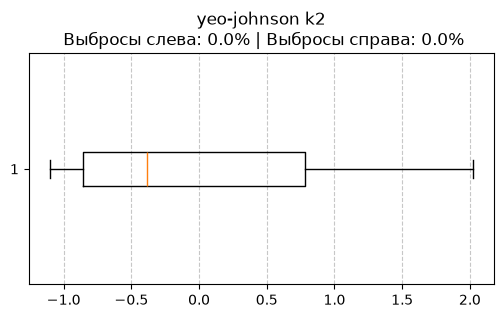

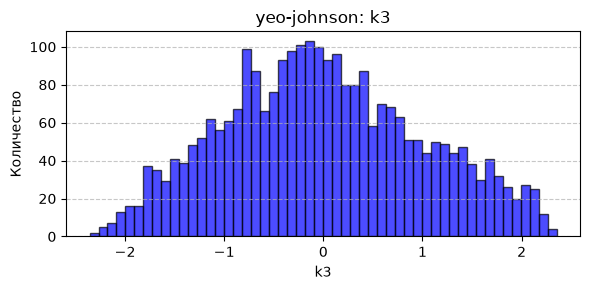

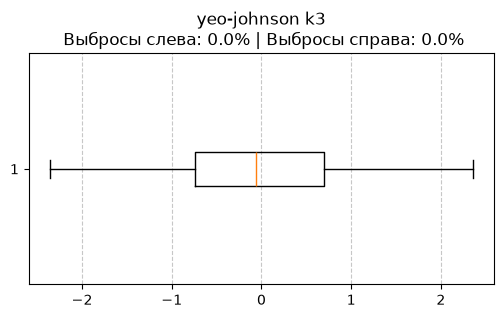

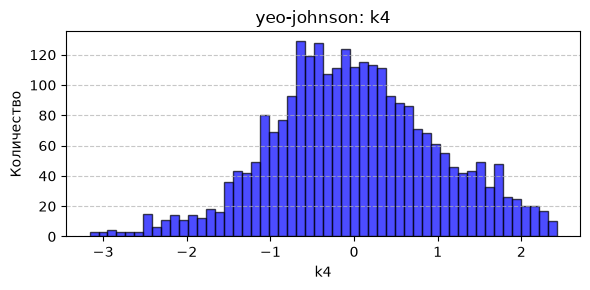

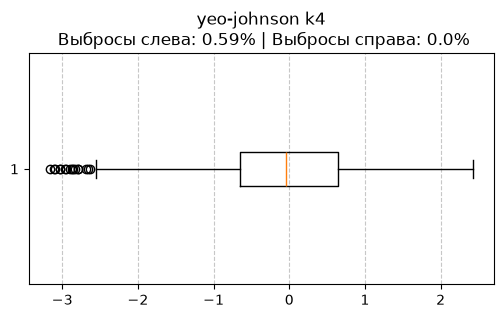

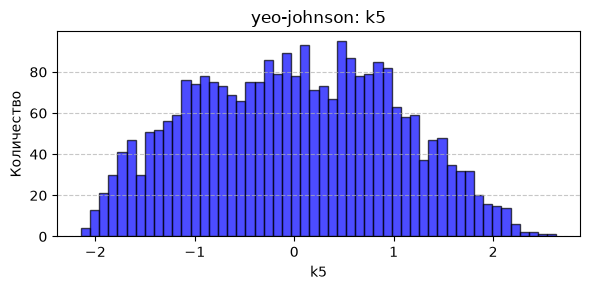

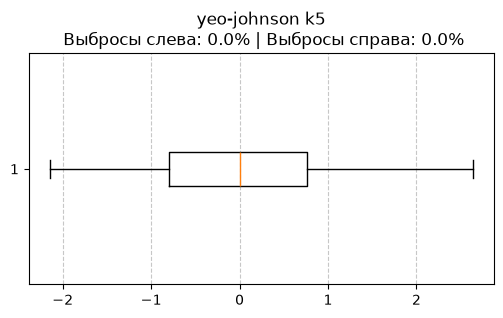

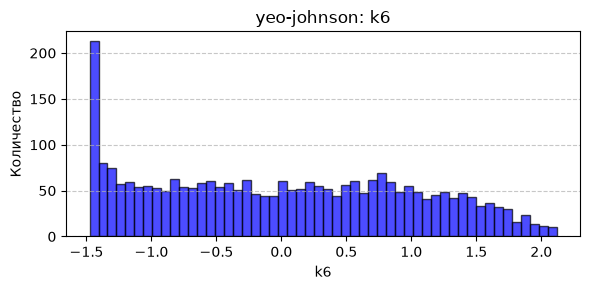

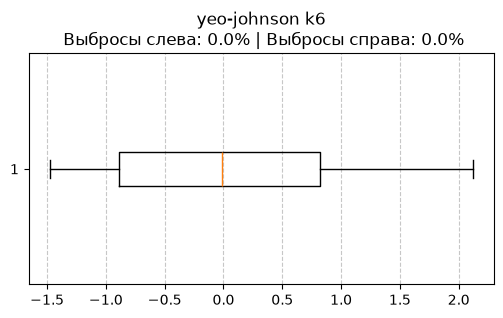

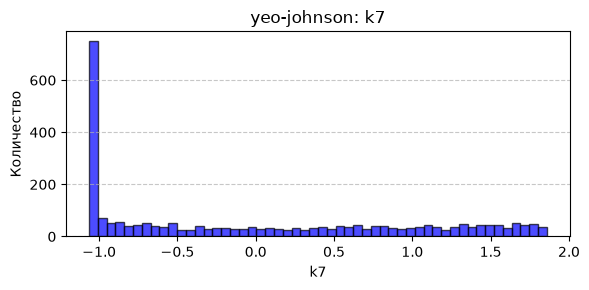

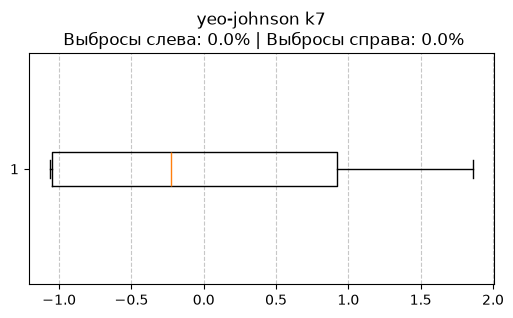

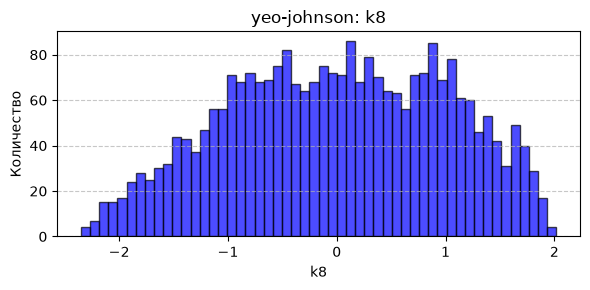

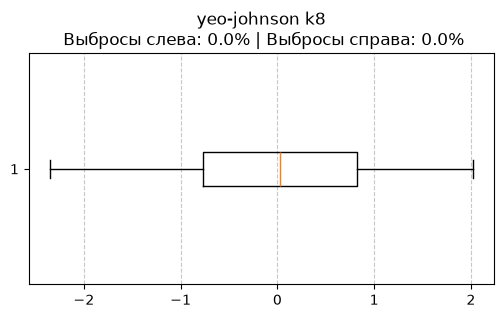

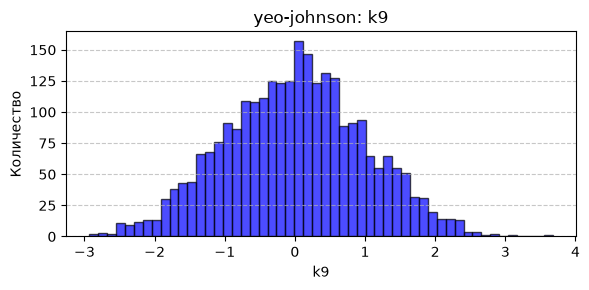

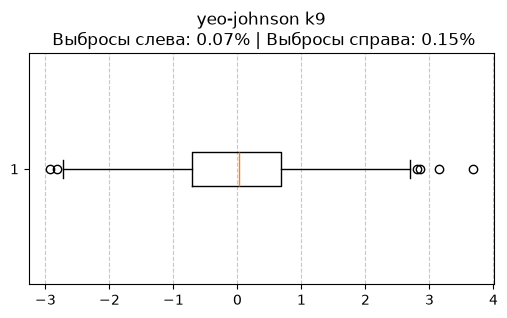

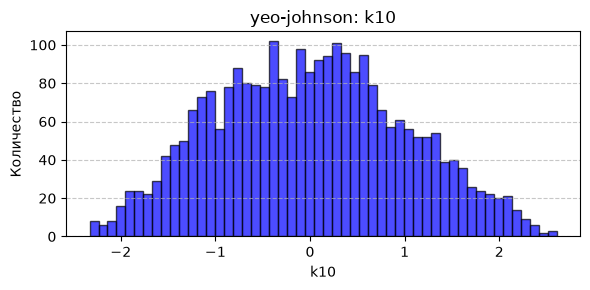

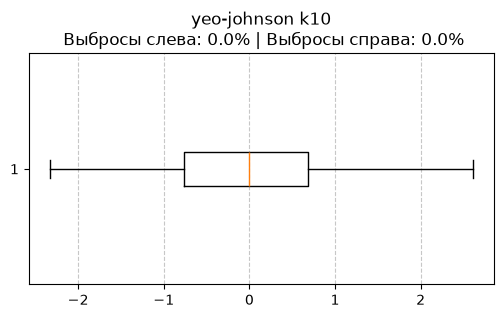

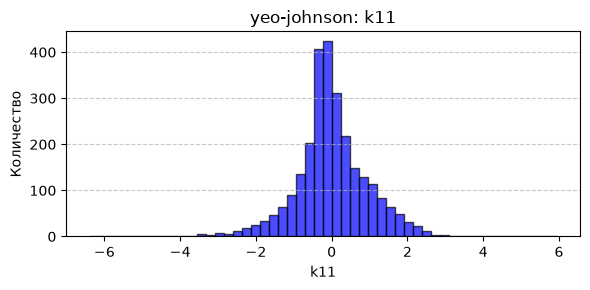

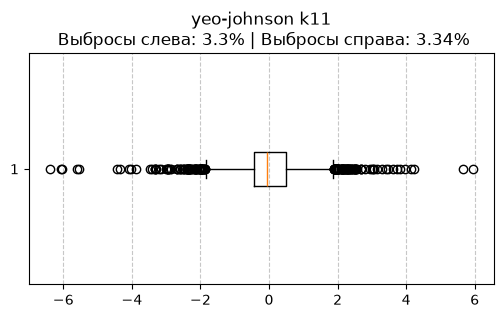

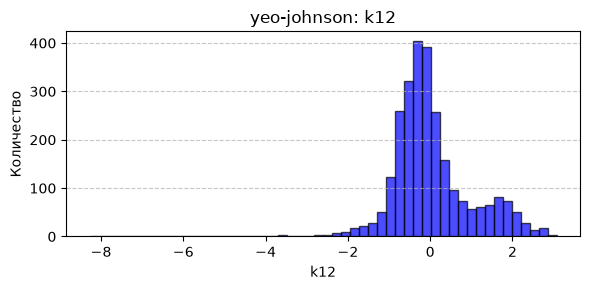

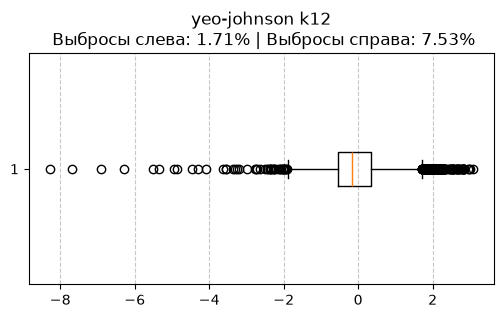

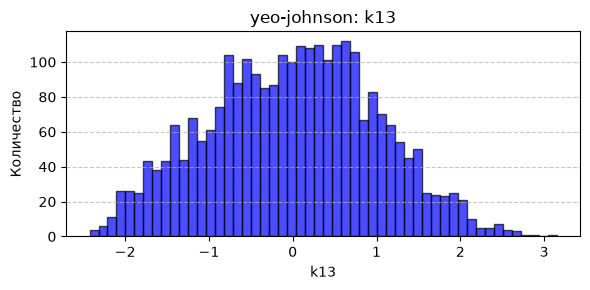

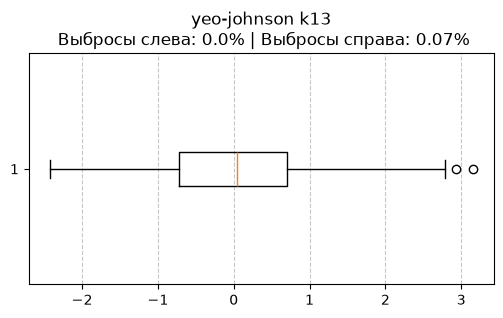

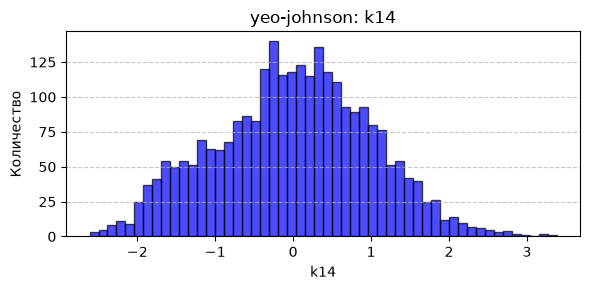

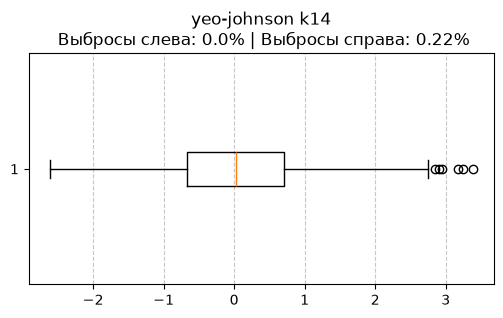

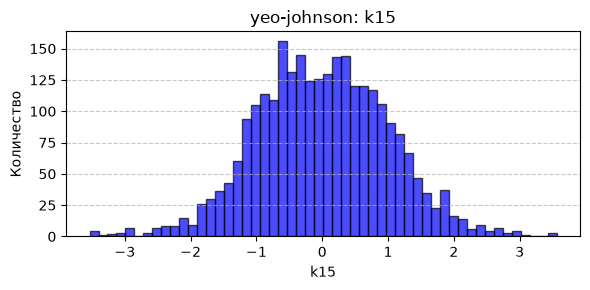

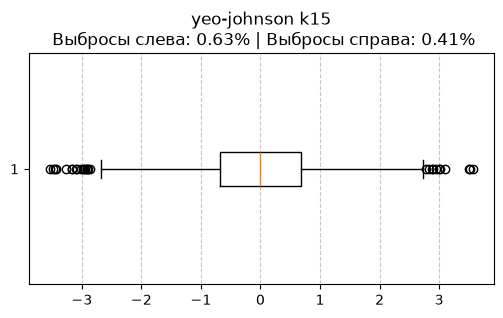

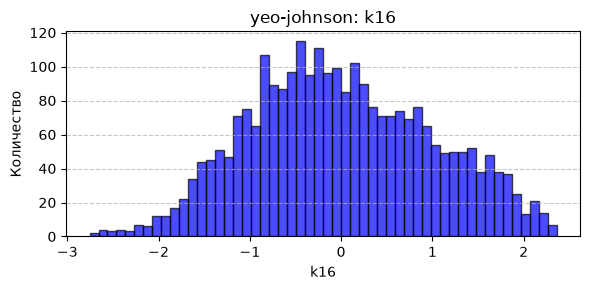

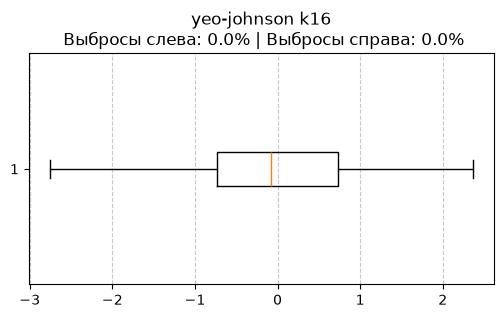

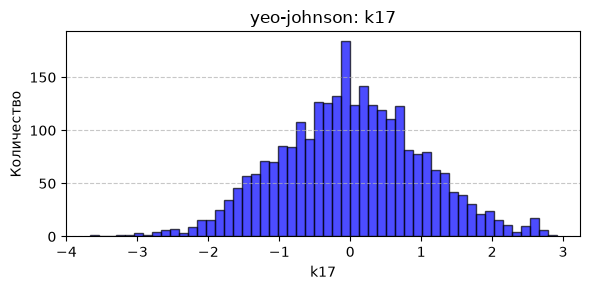

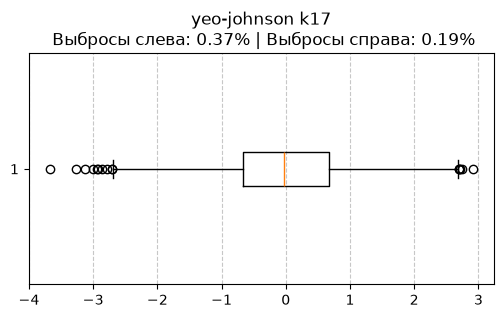

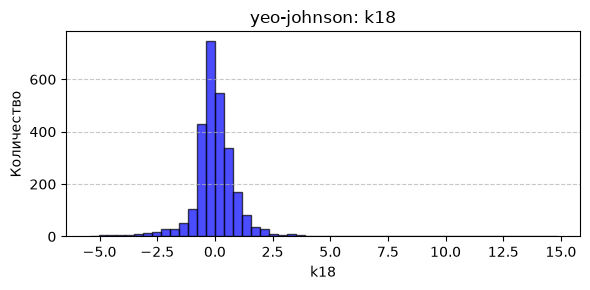

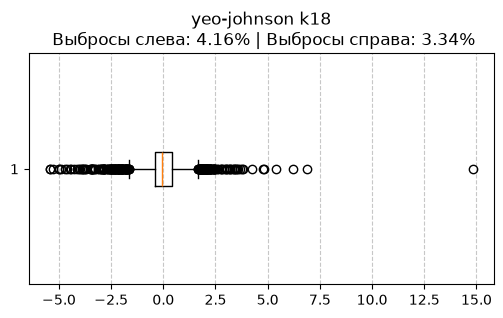

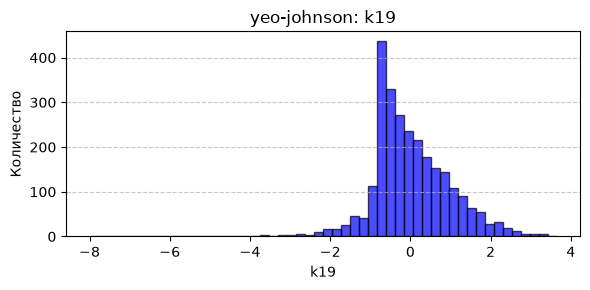

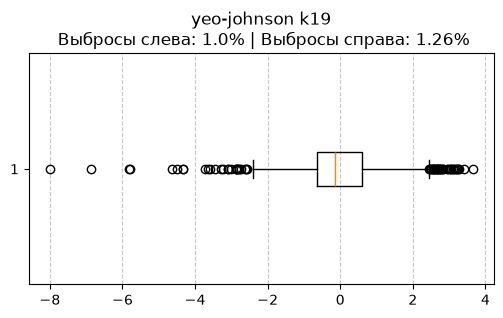

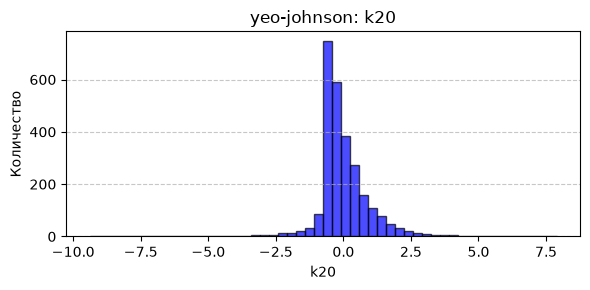

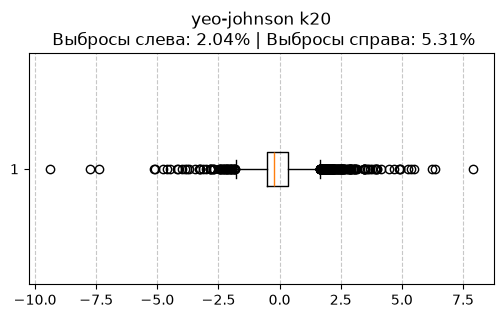

In [8]:
pt = PowerTransformer(standardize=True, method="yeo-johnson")
df2 = pd.DataFrame(pt.fit_transform(df), columns=df.columns)

for col in num_cols:
    plt.figure(figsize=(6,3))
    plt.hist(df2[col].dropna(), bins=52, color='blue', edgecolor='black', alpha=0.7)
    plt.title(f"yeo-johnson: {col}")
    plt.xlabel(col)
    plt.ylabel("Количество")
    plt.grid(axis='y', linestyle='--', alpha = 0.7)
    plt.tight_layout() 
    plt.savefig(f'{outdir}/{col}_hist3.png')
    plt.show()

    plt.figure(figsize=(6,3))
    bp = plt.boxplot(df2[col].dropna(), orientation='horizontal')

    total_count = len(df2[col].dropna())
    left_whisker = bp['whiskers'][0].get_xdata()[0]   
    right_whisker= bp['whiskers'][1].get_xdata()[1]
    noise = bp['fliers'][0].get_xdata()

    left_noise_count = len(noise[noise < left_whisker])
    right_noise_count = len(noise[noise > right_whisker])

    if total_count > 0:
        left_prc = round((left_noise_count / total_count) * 100, 2)
        right_prc = round((right_noise_count / total_count) * 100, 2)
    else:
        left_prc = right_prc = 0.0

    summary[col] = {
        'total_count': total_count,
        'left_noise_count': left_noise_count,
        'right_noise_count': right_noise_count,
        'left_prc': left_prc,
        'right_prc': right_prc
    }


    plt.title(f"yeo-johnson {col}\n Выбросы слева: {left_prc}% | Выбросы справа: {right_prc}%")
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.savefig(f'{outdir}/{col}_box4.png')
    plt.show()


In [9]:

for col in num_cols:
    prefixes = ['hist1', 'box1', 'hist2', 'box2', 'box3', 'hist4', 'box5', 'hist3', 'box4']
    
    html_row = f"<div style='margin-bottom: 20px;'><h3>Признак: {col}</h3><div style='display: flex; gap: 20px; overflow-x: auto;'>"
    
    has_images = False
    for prefix in prefixes:
        filename = f"{col}_{prefix}.png"
        filepath = os.path.join(outdir, filename)
        
        if os.path.exists(filepath):

            html_row += f"""
            <div style='text-align: center;'>
                <span style='font-size: 12px; color: gray; display: block;'>{prefix}</span>
                <img src='{filepath}' style='max-width: 400px; height: auto; padding: 15px;' />
            </div>
            """
            has_images = True
            
    html_row += "</div></div>"
    
    if has_images:
        display(HTML(html_row))


После масштабирования имеем среднее 0 и дисперсию 1

# КОРРЕЛЯЦИОННЫЙ АНАЛИЗ

ЗАДАЧИ ИССЛЕДОВАНИЯ:
1. Получить матрицу парных коэффициентов корреляции для всех имеющихся
показателей.
2. Выявить переменные, имеющие наиболее тесные взаимосвязи, а также
проанализировать знаки показателей корреляции.
3. Выделить переменные, которые возможно исключить из дальнейшего анализа в
силу существования тесной связи с другой/ими переменной/ыми.

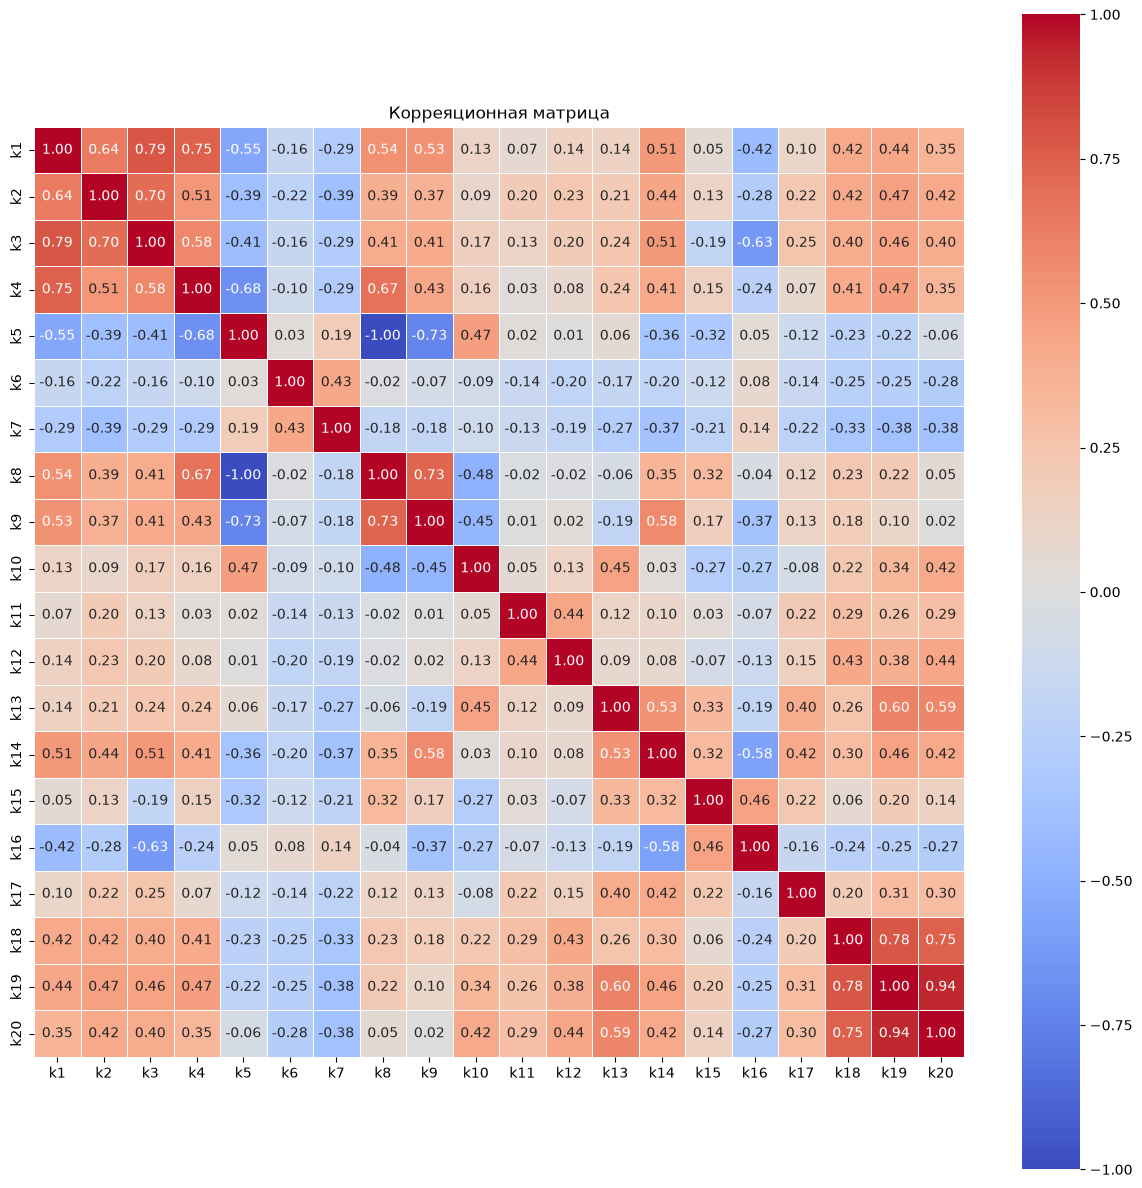

In [10]:
corr_matrix = df_scaled2[num_cols].corr(method='spearman')
plt.figure(figsize=(15,15))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1, vmax=1,
    linewidths=0.4,
    square=True     
)
plt.title('Корреяционная матрица')
plt.show()

df_final = df_scaled2.drop(columns=['k3', 'k8', 'k18', 'k20'])

In [11]:
import factor_analyzer.factor_analyzer
from sklearn.utils import check_array as _original_check_array

def patched_check_array(*args, **kwargs):
    if 'force_all_finite' in kwargs:
        kwargs['ensure_all_finite'] = kwargs.pop('force_all_finite')
    return _original_check_array(*args, **kwargs)

factor_analyzer.factor_analyzer.check_array = patched_check_array

from factor_analyzer import FactorAnalyzer

высокие корреляции у признаков К19-К20, К1-К4_new, и полная линейная зависимость у K5-K8

### Лабораторная работа 2  
Факторный анализ. Метод главных компонент

ЗАДАЧИ ИССЛЕДОВАНИЯ
1. Применить факторный анализ (метод главных компонет) к совокупности
анализируемых данных. Проанализировать целесообразность использования данного
метода анализа на основе специальных критериев и тестовых статистик.
2. На основании результатов факторного анализа определить наиболее значимые
коэффициенты, сохраняющие наибольший процент дисперсии исходных показателей.
3. Рассчитать интегральный показатель кредитоспособности как взвешенную
сумму полученных главных компонент. В качестве весов использовать соответствующие
величины процентов объясненной дисперсии

In [12]:
from factor_analyzer import calculate_bartlett_sphericity, calculate_kmo, FactorAnalyzer
from sklearn.decomposition import PCA

Критерий сферичности Бартлетта  
$$\chi^2 = - \left( n - 1 - \frac{2p + 5}{6} \right) \cdot \ln|R|$$

* $\chi^2$ — вычисляемое значение статистики Хи-квадрат.
* $n$ — объем выборки (количество наблюдений/строк в данных).
* $p$ — количество исходных переменных (столбцов).
* $|R|$ — определитель (детерминант) корреляционной матрицы исходных данных.  
$H_0$ = {корелляционная матрица является единичной}  

Статистика Кайзера−Мейера−Олкина
$$KMO = \frac{\sum_{i \neq j} r_{ij}^2}{\sum_{i \neq j} r_{ij}^2 + \sum_{i \neq j} a_{ij}^2}$$

* $r_{ij}$ — парный (обычный) коэффициент корреляции Пирсона между переменной $i$ и переменной $j$.
* $a_{ij}$ — коэффициент частной корреляции между переменной $i$ и переменной $j$ при исключении влияния всех остальных переменных модели.  
Частным (условным) коэффициентом корреляции непрерывных случайных величин $X, Y$ при условии, что значение $Z$ фиксировано (влияние $Z$ «вычтено»), называется характеристика:

$$\rho_{X,Y|Z} = \frac{\rho_{X,Y} - \rho_{X,Z}\rho_{Y,Z}}{\sqrt{(1 - \rho_{X,Z}^2)(1 - \rho_{Y,Z}^2)}} \in [-1, 1]$$

Где:
* $\rho_{X,Y}$, $\rho_{X,Z}$, $\rho_{Y,Z}$ — обычные парные коэффициенты корреляции Пирсона между соответствующими парами переменных.



In [13]:
xi2, p_value = calculate_bartlett_sphericity(df_final)
print(f"Хи-квадрат: {xi2:.3f}")
print(f"p-value: {p_value:.5f}")

kmo_all, kmo_model = calculate_kmo(df_final)
print(f"Общий индекс КМО: {kmo_model:.3f}")

Хи-квадрат: 17496.883
p-value: 0.00000
Общий индекс КМО: 0.678


d:\DP1\.venv\Lib\site-packages\factor_analyzer\utils.py:244: UserWarning: The inverse of the variance-covariance matrix was calculated using the Moore-Penrose generalized matrix inversion, due to its determinant being at or very close to zero.
  warnings.warn(


таким образом нулевая гипотеза о единичной матрице корреляций отвергается и индекс КМО свидетельствует о приемлемом качестве выборки для
применения факторного анализа

### 1. Центрирование матрицы данных
Сдвиг каждого признака к нулевому среднему значению:
$$\tilde{x}_{ij} = x_{ij} - \mu_j$$

$$\tilde{X} = X - \mu$$

### 2. Сингулярное разложение (SVD)
Разложение центрированной матрицы $\tilde{X}$ вместо построения тяжелой матрицы ковариаций:
$$\tilde{X} = U \cdot \Sigma \cdot V^T$$

* $U$ — левые сингулярные векторы (размер $n \times n$).
* $\Sigma$ — диагональная матрица сингулярных чисел $\sigma_k$ (размер $n \times p$).
* $V^T$ — правые сингулярные векторы / собственные векторы (размер $p \times p$).

### 3. Расчет дисперсии (Собственные значения)
Связь сингулярных чисел $\sigma_k$ с собственными значениями матриц ковариации $\lambda_k$:
$$\lambda_k = \frac{\sigma_k^2}{n - 1}$$

Доля объясненной дисперсии для $k$-й компоненты:
$$\text{Variance Ratio}_k = \frac{\lambda_k}{\sum_{j=1}^{p} \lambda_j}$$

### 4. Трансформация (Проекция в новое пространство)
Математическая проекция исходных центрированных точек на новые оси:
$$X_{pca} = \tilde{X} \cdot V_k$$

Оптимизированная формула:
$$X_{pca} = U_k \cdot \Sigma_k$$



In [14]:
n_components = 5

pca1 = PCA(n_components=n_components, random_state=42)
X_pca1 = pca1.fit_transform(df_final)

variance_ratio = pca1.explained_variance_ratio_
cumulative_variance = np.cumsum(variance_ratio)

print("PCA без вращения")
for i in range(n_components):
    print(
        f"Компонента {i+1}: Дисперсия = {variance_ratio[i]*100:.2f}%, Накопленная = {cumulative_variance[i]*100:.2f}%"
    )

df_pca1 = pd.DataFrame(
    X_pca1,
    index=df_final.index,
    columns=[f"pc{i+1}" for i in range(n_components)],
)

df_corr1 = pd.DataFrame(index=df_final.columns)
for col in df_pca1.columns:
    df_corr1[col] = df_final.corrwith(df_pca1[col])
print("Факторные нагрузки без вращения:")
print(df_corr1)
#--------------------------------------------

pca2 = FactorAnalyzer(n_factors=n_components, method='principal', rotation='quartimax')
X_pca2 = pca2.fit_transform(df_final)
pca2_variance, pca2_variance_ratio, pca2_cumulative_variance = pca2.get_factor_variance()
df_pca2 = pd.DataFrame(
    X_pca2,
    index=df_final.index,
    columns=[f"rc{i+1}" for i in range(n_components)],
)
print("PCA с вращением")
for i in range(n_components):
    print(
        f"Компонента {i+1}: Дисперсия = {pca2_variance_ratio[i]*100:.2f}%, Накопленная = {pca2_cumulative_variance[i]*100:.2f}%"
    )

df_corr2 = pd.DataFrame(index=df_final.columns)
for col in df_pca2.columns:
    df_corr2[col] = df_final.corrwith(df_pca2[col])
print("Факторные нагрузки с вращения:")
print(df_corr2)

PCA без вращения
Компонента 1: Дисперсия = 23.66%, Накопленная = 23.66%
Компонента 2: Дисперсия = 14.33%, Накопленная = 37.99%
Компонента 3: Дисперсия = 11.35%, Накопленная = 49.34%
Компонента 4: Дисперсия = 9.54%, Накопленная = 58.88%
Компонента 5: Дисперсия = 8.98%, Накопленная = 67.86%
Факторные нагрузки без вращения:
          pc1       pc2       pc3       pc4       pc5
k1  -0.706808 -0.233826  0.150199 -0.364529 -0.033110
k2  -0.599645 -0.131235  0.151888 -0.198855 -0.024950
k4  -0.696658 -0.174799 -0.006645 -0.258158 -0.017328
k5   0.559427  0.570563 -0.321975 -0.112174  0.013839
k6   0.382964 -0.312747 -0.011535 -0.271427  0.520991
k7   0.608149 -0.205395  0.087146 -0.222476  0.414419
k9  -0.524291 -0.532167  0.393999 -0.088943  0.018883
k10 -0.086610  0.556150 -0.443528 -0.455551  0.015816
k11 -0.068439  0.276149  0.193379  0.093685  0.125573
k12 -0.222030  0.686633  0.626904  0.095029  0.186268
k13 -0.437474  0.295122 -0.669719  0.136732  0.118286
k14 -0.735464 -0.173184 -0.21

После применения процедуры вращения наиболее тесно коррелируют:  
1 - k1, k2, k3, k4  
2 - k9, k10  
3 - k15, k16  
4 - k11, k12  
5 - k13, k14

### Расчет интегрального показателя кредитоспособности

Для каждого предприятия интегральный показатель $I$ рассчитывается как взвешенная сумма полученных главных компонент по формуле:

$$I = \frac{w_{1} \cdot rc_{1} + w_{2} \cdot rc_{2} + w_{3} \cdot rc_{3} + w_{4} \cdot rc_{4} + w_{5} \cdot rc_{5}}{w_{1} + w_{2} + w_{3} + w_{4} + w_{5}}$$

Где:
* $rc_{1}, \dots, rc_{5}$ — значения 5 главных компонент для конкретного предприятия.
* $w_{1}, \dots, w_{5}$ — доли объясненной дисперсии для этих компонент


In [15]:
weights = pca2_variance_ratio

integral_index = (X_pca2 @ weights) / np.sum(weights)

df_pca2['integral_index'] = integral_index

print(df_pca2[['integral_index']].head())


   integral_index
0       -0.758773
1       -0.253856
2       -1.002369
3        1.569938
4       -0.659406
